<a href="https://colab.research.google.com/github/amavi-e/A-TinyML-Powered-Wearable-Navigation-Aid-for-the-Visually-Impaired/blob/preprocessing/irp_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FYP dataset v4 - EDA, preprocessing (with viewpoint filter) and final dataset
TinyML wearable navigation aid. One notebook, three parts. Use a **CPU runtime** (no GPU needed). Run the cells top to bottom.

**Part A - Setup (cells 0-4):** settings, class schema, helpers, loaders. Run these first in every session.

**Part B - EDA (cells 5a-6):** one cell per dataset, then a combined view (duplicates across datasets, photos available per class).

**New in v4:** (1) a viewpoint filter that rejects aerial / drone views, extreme close-ups, studio-style photos and photos with black privacy boxes (cell 2 defines it, cell 6b measures it, cell 8 applies it); (2) much more EDA (cells 6c, 6d and 10b): label ambiguity, class co-occurrence, size / shape / position of objects, brightness, sharpness, colour, average pictures, contact sheets and a train / val / test similarity check. The result is written to `final_dataset_v4` and `final_dataset_v4.tar`, so the verified v3 dataset stays untouched.

**Part C - Preprocessing (cells 7-10, including the repair cell 9b):** leak-free split, build the final dataset (1000 images per class), save to Drive, verify.

If the runtime disconnects: run Part A again, then continue. Reading results are cached on Drive (`FYP/cache_v3`) and finished class folders are skipped when you re-run cell 8.

## Part A - Setup

In [ ]:
# CELL 0 - SETUP: imports, Drive, folders and global settings. Run this first in every session.
import os, re, json, time, random, shutil, hashlib, csv, math, subprocess   # standard-library tools used below
import xml.etree.ElementTree as ET   # parser for Pascal-VOC xml label files
from pathlib import Path   # object-style file paths
from collections import defaultdict, Counter, deque   # grouped dicts, counters and queues
from concurrent.futures import ThreadPoolExecutor   # runs file reads in parallel threads
import numpy as np, cv2   # arrays and OpenCV for image work
from PIL import Image   # reads an image header (its size) without decoding the whole image
import matplotlib.pyplot as plt   # charts and image grids

DRIVE = '/content/drive/MyDrive'   # where Google Drive appears inside Colab
try:   # only Colab has the google.colab package
    from google.colab import drive   # Colab's helper for mounting Drive
    if not os.path.ismount('/content/drive'):   # mount only when Drive is not mounted yet
        drive.mount('/content/drive')   # asks you to allow Drive access
except ImportError:   # we are not running inside Colab
    pass   # nothing to mount

DS = f'{DRIVE}/FYP/dataset'   # folder that holds all the raw datasets
CACHE = f'{DRIVE}/FYP/cache_v3'   # cached label/size reads on Drive (survives a runtime reset)
LOCAL_JSON = '/content/outdoor_json'   # local copy of the 3 outdoor annotation files (Drive reads fail often)
EDA_DIR = '/content/eda_v3'   # EDA pictures are saved here
FINAL_LOCAL = '/content/final_dataset'   # the final dataset is BUILT here (fast local disk)
FINAL_DRIVE = f'{DRIVE}/FYP/final_dataset_v4'   # ...then copied here as a normal folder you can open
FINAL_TAR = f'{DRIVE}/FYP/final_dataset_v4.tar'   # ...and archived here as ONE file (best for training)
for d in (CACHE, LOCAL_JSON, EDA_DIR):   # make sure each working folder exists
    os.makedirs(d, exist_ok=True)   # create it if missing

SIZE = 320   # every final image is a 320x320 square
SEED = 42   # fixed random seed so every run gives the same dataset
MIN_AREA = 0.003   # a box smaller than 0.3% of the final frame is dropped (too tiny to see)
MAX_AREA = 0.95   # a box bigger than 95% of the final frame is dropped (it fills the whole picture)
MIN_SIDE = 0.02   # a box thinner than 2% of the frame (either side) is dropped
BG_MIN_AREA = 0.02   # tree/bushes lose "largest box" status if another class covers at least 2% of the frame
PHASH_T = 4   # two images whose 64-bit hashes differ in <= 4 bits are treated as the same photo
TOTAL_PER_CLASS = 1000   # images per class in the final dataset (all splits together)
SPLIT_FRAC = {'train': 0.8, 'val': 0.1, 'test': 0.1}   # share of each class that goes to each split
QUOTA = {s: round(TOTAL_PER_CLASS * f) for s, f in SPLIT_FRAC.items()}   # images per class per split (800/100/100)
VIEWPOINT_FILTER = True   # reject photos that are not a useful walking viewpoint (aerial, extreme close-up, studio style) while the dataset is built
VP_RULES = {'closeup', 'studio', 'blackbox', 'sky'}   # the rules that reject a photo; 'aerial' (its line test flagged ordinary ground-level photos: trains, birds, horses, a cat), 'upward', 'tilt', 'blurry' and 'uniform' also exist but are OFF (add them here to switch them on)
VP_SKY_SHARE = 0.6   # the 'sky' rule: at least this share of the picture is open sky (blue, or pale overcast), so the object floats in the sky and is not an obstacle on the ground
VP_SKY_CLASSES = {'traffic light'}   # the 'sky' rule is applied to these classes only (a tree or a stop sign against the sky is still a normal photo)
VP_EXEMPT = {'stairs': {'aerial'}, 'crosswalk': {'aerial'}, 'pothole': {'aerial'}, 'tv': {'blackbox'}, 'object': {'blackbox'}}   # rule switched off for these classes: stairs / crosswalk stripes are horizontal lines by nature and potholes look down at the ground (so the line test would call them aerial); a switched-off tv screen or a laptop / oven / microwave glass is a real black rectangle (so the black-box test would wrongly remove them)
VP_CLOSEUP_FILL = 0.5   # the 'closeup' rule only applies when the labelled object covers at least this share of the picture (a plain sky with a small bird or traffic light is not a close-up)
VP_WHITE_EDGE = 0.85   # a photo whose whole frame (all four edges) is at least this share near-white counts as a studio / product shot
BB_LEVEL = 3   # a pixel darker than this (0-255) counts as 'black' when looking for redaction boxes
BB_MIN_AREA = 0.003   # a black rectangle must cover at least this share of the picture (0.3 percent) to count as a redaction box
BB_FILL = 0.97   # ... and fill at least this share of its own bounding rectangle (a solid box, not a dark shadow)
BB_COUNT = 1   # a photo with at least this many black boxes is rejected by the 'blackbox' rule (black bars along the picture edge are padding and never count)
VP_LONG_SIDE = 640   # photos are shrunk to this long side before the checks, so the pixel-based tests behave the same for every source
QUAL = dict(min_side=64, min_mean=15, max_mean=240, min_std=8)   # image quality limits (size, brightness, contrast)
CW_BLOCK = 25   # crosswalk frames numbered within the same block of 25 count as one scene
DOOR_BLOCK = 10   # door photos numbered within the same block of 10 count as one scene
DOOR_MASK_VALUE = 1   # pixel value that means "door or door frame" in the Door Detection masks
TM_MIN = 0.90   # minimum template-match score to trust a recovered door box
WORKERS = 4   # parallel threads for reading files
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}   # file extensions treated as images
print('Quota per class per split:', QUOTA, '| total per class:', sum(QUOTA.values()))   # confirm the settings


Quota per class per split: {'train': 800, 'val': 100, 'test': 100} | total per class: 1000


In [ ]:
# CELL 1 - CLASS SCHEMA: the final classes, which raw classes merge into them, and the name mappings.
CLASS_LIST = [   # the final classes, in id order (id = position in this list)
    'person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign',   # road users and street furniture
    'fire hydrant', 'bench', 'stairs', 'chair', 'couch', 'table', 'door', 'bed', 'toilet',   # obstacles and indoor items
    'sink', 'tv', 'dog', 'cat', 'bird', 'animal', 'object', 'crosswalk', 'vegetation', 'pothole']   # animals, groups and ground hazards
CLASS_ID = {n: i for i, n in enumerate(CLASS_LIST)}   # class name -> id
NC = len(CLASS_LIST)   # number of final classes
MEMBERS = {   # merged classes -> the raw classes inside them (balanced equally inside the class)
    'vegetation': ['tree', 'bushes', 'potted plant'],   # all plants
    'object': ['backpack', 'handbag', 'umbrella', 'laptop', 'refrigerator', 'oven', 'microwave',   # carried / household items
               'clock', 'vase', 'suitcase', 'traffic cone'],   # ...plus suitcase and traffic cone
    'animal': ['horse', 'cow', 'sheep', 'elephant', 'bear', 'zebra', 'giraffe'],   # large animals
    'door': ['door', 'elevator'],   # doors and elevator doors
}   # end of the merged-class table
MEMBER_LIST = [m for c in CLASS_LIST for m in MEMBERS.get(c, [c])]   # every member, grouped by class (single-member classes use their own name)
MEMBER_ID = {m: i for i, m in enumerate(MEMBER_LIST)}   # member name -> member id
MEMBER_CLASS = {m: CLASS_ID[c] for c in CLASS_LIST for m in MEMBERS.get(c, [c])}   # member name -> final class id
BACKGROUND_MEMBERS = {'tree', 'bushes'}   # usually scenery, so they rarely decide the label of a picture
COCO_ALIAS = {'dining table': 'table'}   # COCO names that differ from our member names
OUTDOOR_ALIAS = {   # outdoor-set names (after lower-casing and '_' -> ' ') that differ from our member names
    'scooter': 'motorcycle', 'green light': 'traffic light',   # scooters count as motorcycles; coloured lights are traffic lights
    'red light': 'traffic light', 'yellow light': 'traffic light'}   # (the other two light colours)
EXTRA_MAP = {   # raw label name -> member for the downloaded sources ('*' = any name; YOLO files give 'id0','id1',...)
    'stairs1': {'*': 'stairs'},   # every Stairs1 box is stairs
    'stairs2': {'upstair': 'stairs', 'downstair': 'stairs'},   # up and down stairs are both stairs
    'pothole1': {'*': 'pothole'},   # every PothRGBD polygon is a pothole
    'pothole2': {'pothole': 'pothole'},   # Pothole2 has one class
    'crosswalk': {'id0': 'crosswalk'},   # id0 = crosswalk; id1 = guide arrows is ignored (not in the map)
    'doors': {'door': 'door'},   # door boxes recovered from the Doors dataset
}   # end of the downloaded-source name maps

def norm(name):   # normalise a raw class name
    return name.strip().lower().replace('_', ' ')   # lower-case, underscores become spaces

def resolve_member(src, raw):   # raw class name from dataset `src` -> member name (or None = not a class we need)
    if src in ('coco', 'outdoor'):   # the two big datasets use name aliases
        n = norm(raw)   # normalise the name
        n = (COCO_ALIAS if src == 'coco' else OUTDOOR_ALIAS).get(n, n)   # apply the alias table for that dataset
        return n if n in MEMBER_ID else None   # keep only names that are members of our classes
    m = EXTRA_MAP[src]   # the downloaded sources use explicit maps
    return m.get(raw.lower(), m.get('*'))   # exact name first, then the '*' catch-all

print(f'{NC} final classes; {len(MEMBER_LIST)} members')   # summary
for c in MEMBERS:   # show every merged class
    print(f'  {c:11s} <- {MEMBERS[c]}')   # and what it contains


27 final classes; 46 members
  vegetation  <- ['tree', 'bushes', 'potted plant']
  object      <- ['backpack', 'handbag', 'umbrella', 'laptop', 'refrigerator', 'oven', 'microwave', 'clock', 'vase', 'suitcase', 'traffic cone']
  animal      <- ['horse', 'cow', 'sheep', 'elephant', 'bear', 'zebra', 'giraffe']
  door        <- ['door', 'elevator']


In [ ]:
# CELL 2 - HELPERS: safe file reading, box geometry, filters, hashing, label parsers. Definitions only.
def retry(fn, tries=5, wait=3):   # run fn(); if Drive raises an OSError (Errno 5 etc.), wait and try again
    for t in range(tries):   # up to `tries` attempts
        try:   # attempt the operation
            return fn()   # success: return its result
        except OSError:   # Drive hiccup
            if t == tries - 1:   # last attempt failed
                raise   # give up and show the error
            time.sleep(wait * (t + 1))   # wait a little longer each time

def read_text(p):   # read a text/label file safely
    def _r():   # inner function so retry can repeat it
        with open(p, encoding='utf-8', errors='ignore') as f:   # open ignoring odd characters
            return f.read().lstrip('﻿')   # return the text without a leading BOM
    return retry(_r)   # retry on Drive errors

def read_img(p):   # read an image as BGR pixels with EXIF rotation IGNORED (labels refer to the raw pixels)
    def _r():   # inner function so retry can repeat it
        return cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)   # decode from raw bytes
    return retry(_r)   # retry on Drive errors

def read_gray(p):   # read an image as grey pixels (used for hashing and template matching)
    def _r():   # inner function so retry can repeat it
        return cv2.imdecode(np.fromfile(str(p), dtype=np.uint8), cv2.IMREAD_GRAYSCALE | cv2.IMREAD_IGNORE_ORIENTATION)   # grey decode
    return retry(_r)   # retry on Drive errors

def img_size(p):   # (width, height) from the file header only
    def _r():   # inner function so retry can repeat it
        with Image.open(p) as im:   # open lazily (no pixel decode)
            return im.size   # raw size, EXIF rotation not applied
    return retry(_r)   # retry on Drive errors

def listdir(d):   # list a folder's file names safely
    return retry(lambda: os.listdir(d))   # retry on Drive errors

def write_json(path, obj):   # write JSON to Drive safely (local temp file first, then copy)
    tmp = '/content/_tmp_write.json'   # local temp file
    with open(tmp, 'w') as f:   # write locally (fast, never fails)
        json.dump(obj, f)   # serialise the object
    retry(lambda: shutil.copyfile(tmp, path))   # copy to the destination with retries

def cached(name, fn):   # run fn() once and keep its JSON result in the Drive cache folder
    path = f'{CACHE}/{name}.json'   # cache file for this name
    if os.path.exists(path):   # computed before
        return json.loads(read_text(path))   # reuse it
    out = fn()   # compute now
    write_json(path, out)   # save for next time
    return out   # return the result

def source_key(fname):   # Roboflow copies are named '<original>.rf.<hash>.jpg'; same text before '.rf.' = same photo
    return fname.split('.rf.')[0]   # the part before '.rf.'

def label_stem(fname):   # label file name -> image stem ('a.jpg.txt' and 'a.txt' both give 'a')
    return re.sub(r'\.(jpe?g|png|bmp|webp)$', '', Path(fname).stem, flags=re.I)   # drop a leftover image extension

def safe_stem(s):   # make a string safe for file names
    return re.sub(r'[^A-Za-z0-9_\-]+', '_', s)   # replace odd characters by '_'

def out_stem(src, name):   # unique, safe output file name for an image (hash suffix avoids collisions)
    return f"{src}_{safe_stem(Path(name).stem)[:60]}_{hashlib.md5((src + name).encode()).hexdigest()[:6]}"   # source + short name + 6-char hash

def folder_name(cls):   # class name -> folder name
    return cls.replace(' ', '_')   # spaces become underscores

# ---------- letterbox geometry: image AND boxes go through the same transform ----------
def letterbox_params(w, h):   # how an w x h image is scaled and padded into SIZE x SIZE
    scale = SIZE / max(w, h)   # scale so the long side becomes SIZE
    nw, nh = int(round(w * scale)), int(round(h * scale))   # resized width and height
    return scale, (SIZE - nw) // 2, (SIZE - nh) // 2, nw, nh   # scale, left pad, top pad, new size

def letterbox(img):   # resize keeping aspect ratio and pad with grey (114) to SIZE x SIZE
    h, w = img.shape[:2]   # original height and width
    scale, px, py, nw, nh = letterbox_params(w, h)   # geometry
    canvas = np.full((SIZE, SIZE, 3), 114, np.uint8)   # grey square canvas
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR   # best interpolation for shrinking / enlarging
    canvas[py:py + nh, px:px + nw] = cv2.resize(img, (nw, nh), interpolation=interp)   # paste the resized image in the middle
    return canvas   # the letterboxed image

def final_box(x1, y1, x2, y2, w, h):   # pixel box in the original image -> normalised (cx, cy, bw, bh) in the letterboxed frame
    scale, px, py, _, _ = letterbox_params(w, h)   # same geometry as the image
    return (((x1 + x2) / 2 * scale + px) / SIZE, ((y1 + y2) / 2 * scale + py) / SIZE,   # centre x, centre y
            (x2 - x1) * scale / SIZE, (y2 - y1) * scale / SIZE)   # width, height

def keep_box(bw, bh):   # does a box survive the size filters (judged in the final frame)?
    return MIN_AREA < bw * bh < MAX_AREA and bw >= MIN_SIDE and bh >= MIN_SIDE   # area and side limits

def to_final_boxes(objs, w, h, src):   # objs [(raw_name,x1,y1,x2,y2)] -> boxes [(class_id,cx,cy,bw,bh,member_id)]
    out = []   # surviving boxes
    for raw, x1, y1, x2, y2 in objs:   # go through every labelled object
        m = resolve_member(src, raw)   # which member (if any) is this?
        if m is None:   # not a class we need
            continue   # skip it
        x1, x2 = sorted((max(0.0, float(x1)), min(float(w), float(x2))))   # clip x to the image and order it
        y1, y2 = sorted((max(0.0, float(y1)), min(float(h), float(y2))))   # clip y to the image and order it
        if x2 - x1 <= 1 or y2 - y1 <= 1:   # degenerate (under 1 pixel) box
            continue   # skip it
        cx, cy, bw, bh = final_box(x1, y1, x2, y2, w, h)   # transform into the letterboxed frame
        if keep_box(bw, bh):   # apply the size filters
            out.append((MEMBER_CLASS[m], cx, cy, bw, bh, MEMBER_ID[m]))   # keep with class id and member id
    return out   # list of kept boxes

def primary_box(boxes):   # the box that decides the picture's label: the largest, ignoring tree/bushes when something else is clear
    if not boxes:   # no boxes at all
        return None   # nothing to decide
    area = lambda b: b[3] * b[4]   # box area in the final frame
    fg = [b for b in boxes if MEMBER_LIST[b[5]] not in BACKGROUND_MEMBERS and area(b) >= BG_MIN_AREA]   # clear non-scenery boxes
    return max(fg or boxes, key=area)   # largest of those, else the largest overall

def quality_ok(img):   # reject tiny, nearly black/white or flat images
    h, w = img.shape[:2]   # image size
    if min(h, w) < QUAL['min_side']:   # too small
        return False, 'too small'   # reason
    m, s = float(img.mean()), float(img.std())   # brightness and contrast
    if m < QUAL['min_mean']:   # almost black
        return False, 'too dark'   # reason
    if m > QUAL['max_mean']:   # almost white
        return False, 'too bright'   # reason
    if s < QUAL['min_std']:   # one flat colour
        return False, 'low contrast'   # reason
    return True, ''   # image is fine

# ---------- viewpoint filter: aerial / extreme close-up / studio shots are not what a walking person sees ----------
def _line_angles(edges, w):   # long straight lines in an edge image -> their angles (0 = horizontal, 90 = vertical)
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, 50, minLineLength=int(w * 0.15), maxLineGap=20)   # find long line segments
    if lines is None or len(lines) <= 8:   # too few lines to say anything
        return None   # no verdict
    ang = []   # one angle per line
    for x1, y1, x2, y2 in lines.reshape(-1, 4):   # each segment (reshape works for every OpenCV version)
        a = 90.0 if x2 == x1 else abs(float(np.degrees(np.arctan2(y2 - y1, x2 - x1))))   # angle of the segment
        ang.append(min(a, 180.0 - a))   # fold into 0-90 degrees
    return np.array(ang)   # all angles

def vp_small(img):   # shrink a big photo so the pixel tests behave the same for every source
    h0, w0 = img.shape[:2]   # original size
    if max(h0, w0) <= VP_LONG_SIDE:   # already small enough
        return img   # keep it
    k = VP_LONG_SIDE / max(h0, w0)   # scale factor
    return cv2.resize(img, (max(1, int(w0 * k)), max(1, int(h0 * k))), interpolation=cv2.INTER_AREA)   # smaller copy

def black_boxes(gray):   # grey photo -> list of solid black rectangles (x, y, w, h): privacy redaction boxes
    h, w = gray.shape[:2]   # size
    mask = (gray <= BB_LEVEL).astype(np.uint8)   # 1 where the pixel is black
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))   # fill tiny holes (JPEG noise) inside a box
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)   # every black blob and its bounding rectangle
    out = []   # accepted boxes
    for i in range(1, n):   # skip the background component
        x, y, bw, bh, area = (int(v) for v in stats[i])   # blob geometry
        if area < BB_MIN_AREA * h * w or bw < 16 or bh < 16:   # too small to be a redaction box
            continue   # ignore it
        if area / float(bw * bh) < BB_FILL:   # not a solid rectangle (a shadow, a tyre, a dark corner)
            continue   # ignore it
        touches = x <= 1 or y <= 1 or x + bw >= w - 1 or y + bh >= h - 1   # sits on the picture edge
        if touches and (bw >= 0.9 * w or bh >= 0.9 * h):   # a bar along the whole edge is letterbox padding, not redaction
            continue   # ignore it
        out.append((x, y, bw, bh))   # a black box
    return out   # all black boxes found

def object_fill(c):   # candidate -> share of the photo's own area (without padding) covered by the labelling box
    p = primary_box(c['boxes'])   # the box that decides the label
    _, _, _, nw, nh = letterbox_params(c['w'], c['h'])   # size of the picture inside the padded frame
    return float(min(1.0, p[3] * p[4] / max(nw * nh / SIZE ** 2, 1e-9)))   # box area / picture area

def sky_share(img):   # BGR photo -> share of pixels that look like open sky (blue, or pale grey-white overcast)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)   # hue / saturation / value
    h_, s_, v_ = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]   # the three channels
    blue = (h_ >= 95) & (h_ <= 135) & (s_ >= 40) & (v_ >= 110)   # clear blue sky
    pale = (s_ <= 35) & (v_ >= 185)   # overcast white / pale grey sky
    return float(np.mean(blue | pale))   # share of sky pixels

def viewpoint_reasons(img, fill=1.0):   # BGR photo (+ share of it covered by the labelled object) -> the set of viewpoint rules it triggers
    img = vp_small(img)   # shrink big photos first
    h, w = img.shape[:2]   # size used for the tests
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # grey copy
    out = set()   # triggered rules
    if len(black_boxes(gray)) >= BB_COUNT:   # solid black rectangles (privacy redaction)
        out.add('blackbox')   # the photo has black boxes painted over it
    white = float(np.mean(gray > 230))   # share of near-white pixels
    border = np.concatenate([gray[:20].ravel(), gray[-20:].ravel(), gray[:, :20].ravel(), gray[:, -20:].ravel()])   # the frame around the picture
    if white > 0.45 and float(np.mean(border > 225)) > 0.6:   # mostly white AND the frame is white too (a pale sky with dark corners or ground at the bottom is not a studio shot)
        out.add('studio')   # product photo on a white background
    centre = gray[h // 4:3 * h // 4, w // 4:3 * w // 4].ravel()   # the middle of the picture
    if border.std() < 12 and centre.std() > 40 and white > 0.25:   # clean light surround, busy centre
        out.add('studio')   # stock-photo style
    if float(np.mean(border > 225)) >= VP_WHITE_EDGE:   # all four edges are white: an object cut out on a white background
        out.add('studio')   # product photo
    if float(np.std(cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 1])) < 15:   # almost no colour variation
        out.add('uniform')   # plain background (rule is off by default)
    if cv2.Laplacian(gray, cv2.CV_64F).var() < 8:   # almost no detail
        out.add('blurry')   # out of focus (rule is off by default)
    edges = cv2.Canny(gray, 50, 150)   # edge map
    edge_density = float(np.mean(edges > 0))   # share of edge pixels
    corners = [gray[5:25, 5:25], gray[5:25, w - 25:w - 5], gray[h - 25:h - 5, 5:25], gray[h - 25:h - 5, w - 25:w - 5]]   # four corner patches
    mid = float(np.mean(gray[h // 2 - 20:h // 2 + 20, w // 2 - 20:w // 2 + 20]))   # centre patch brightness
    if all(abs(float(np.mean(c)) - mid) < 20 for c in corners) and edge_density < 0.05 and fill >= VP_CLOSEUP_FILL:   # corners look like the centre, little detail AND the labelled object covers much of the picture
        out.add('closeup')   # one thing fills the whole frame
    if sky_share(img) >= VP_SKY_SHARE:   # mostly open sky
        out.add('sky')   # the object floats in the sky (applied to VP_SKY_CLASSES only)
    ang = _line_angles(edges, w)   # angles of long straight lines
    if ang is not None:   # enough lines to judge
        if np.mean(ang < 15) > 0.80 and np.mean(ang > 75) < 0.05:   # nearly all horizontal, almost no vertical lines
            out.add('aerial')   # top-down view without perspective
        if np.mean((ang > 30) & (ang < 60)) > 0.75:   # mostly diagonal lines
            out.add('tilt')   # camera tilted sideways (rule is off by default)
    top, bottom = float(np.mean(gray[:h // 3])), float(np.mean(gray[2 * h // 3:]))   # brightness of the top and bottom thirds
    if bottom > top * 2.0 and top < 60:   # dark top, bright bottom
        out.add('upward')   # shot from far below (rule is off by default)
    return out   # the triggered rules

def rules_for(cid):   # class id -> the viewpoint rules in force for that class
    rules = VP_RULES - VP_EXEMPT.get(CLASS_LIST[cid], set())   # the global rules minus this class's exemptions
    if CLASS_LIST[cid] not in VP_SKY_CLASSES:   # the sky rule is only for some classes
        rules = rules - {'sky'}   # switch it off for all the others
    return rules   # rules in force

def viewpoint_reject(img, cid, fill=1.0):   # photo + class id + object fill -> the reason to reject it, or '' when it is fine
    rules = rules_for(cid)   # rules in force for this class
    hit = viewpoint_reasons(img, fill) & rules   # triggered rules that matter
    return ','.join(sorted(hit))   # '' when none

# ---------- perceptual hash: finds the same photo under different file names ----------
def phash_gray(g):   # 64-bit hash from a grey image of any size (stretched to 32x32, so resized copies match)
    g = cv2.resize(g.astype(np.float32), (32, 32), interpolation=cv2.INTER_AREA)   # shrink to 32x32
    d = cv2.dct(g)[:8, :8]   # keep the 8x8 low-frequency block of the DCT
    bits = (d > np.median(d)).flatten()   # 1 where a coefficient is above the median
    return int(''.join('1' if b else '0' for b in bits), 2)   # pack the 64 bits into one integer

def phash_img(img_bgr):   # hash of a decoded colour image
    return phash_gray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY))   # convert to grey, then hash

_PH_FILE = f'{CACHE}/phash.json'   # Drive cache of file-hashes
_PH = json.loads(read_text(_PH_FILE)) if os.path.exists(_PH_FILE) else {}   # load earlier hashes if any

def phash_many(paths):   # hash many image files (cached); returns {path: int or None}
    todo = [p for p in dict.fromkeys(paths) if p not in _PH]   # only the files not hashed yet
    def one(p):   # hash one file
        try:   # reading may fail
            return p, phash_gray(read_gray(p))   # hash of the grey pixels
        except Exception:   # unreadable file
            return p, None   # mark as unreadable
    with ThreadPoolExecutor(WORKERS) as ex:   # parallel reads
        for i, (p, h) in enumerate(ex.map(one, todo)):   # results arrive in order
            _PH[p] = h   # remember the hash
            if (i + 1) % 1000 == 0:   # progress every 1000 files
                print(f'  hashed {i + 1:,}/{len(todo):,}')   # show progress
    if todo:   # something new was hashed
        write_json(_PH_FILE, _PH)   # save the cache
    return {p: _PH.get(p) for p in paths}   # hash for every requested path

_POP = np.array([bin(i).count('1') for i in range(1 << 16)], dtype=np.uint8)   # bit-count table for 16-bit numbers
def popcount64(x):   # number of set bits in each uint64 of an array
    m = np.uint64(0xFFFF)   # mask for 16 bits
    return (_POP[x & m] + _POP[(x >> np.uint64(16)) & m] + _POP[(x >> np.uint64(32)) & m] + _POP[(x >> np.uint64(48)) & m])   # sum of four 16-bit counts

def near_dup_pairs(hashes, thr=PHASH_T):   # all index pairs whose hashes differ by <= thr bits
    h = np.array(hashes, dtype=np.uint64)   # hashes as an array
    pairs = []   # result list
    for i in range(len(h) - 1):   # compare each hash with all later ones
        d = popcount64(h[i + 1:] ^ h[i])   # number of differing bits
        for j in np.nonzero(d <= thr)[0]:   # indices that are close enough
            pairs.append((i, i + 1 + int(j)))   # record the pair
    return pairs   # list of (i, j)

class UnionFind:   # groups items that are connected by "same photo" links
    def __init__(self):   # start empty
        self.p = {}   # parent pointers
    def find(self, x):   # root of x's group
        self.p.setdefault(x, x)   # new item is its own root
        while self.p[x] != x:   # walk up to the root
            self.p[x] = self.p[self.p[x]]   # shorten the path as we go
            x = self.p[x]   # step to the parent
        return x   # the root
    def union(self, a, b):   # merge the groups of a and b
        ra, rb = self.find(a), self.find(b)   # their roots
        if ra != rb:   # different groups
            self.p[rb] = ra   # attach one root to the other

# ---------- label parsers ----------
def parse_yolo_text(txt):   # YOLO text -> [(class_id, x1, y1, x2, y2)] normalised; handles box lines and polygon lines
    out = []   # parsed objects
    for line in txt.splitlines():   # one object per line
        v = line.split()   # split into numbers
        if len(v) < 5:   # too short to be an object
            continue   # skip it
        try:   # numbers may be malformed
            cid = int(float(v[0]))   # class id
            nums = [float(x) for x in v[1:]]   # coordinates
        except ValueError:   # bad number
            continue   # skip the line
        if len(nums) == 4:   # box line: cx cy w h
            cx, cy, bw, bh = nums   # unpack
            out.append((cid, cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2))   # corners
        elif len(nums) >= 6 and len(nums) % 2 == 0:   # polygon line: x1 y1 x2 y2 ...
            xs, ys = nums[0::2], nums[1::2]   # separate x and y lists
            out.append((cid, min(xs), min(ys), max(xs), max(ys)))   # tight box around the polygon
    return out   # parsed objects

def parse_voc(txt):   # Pascal-VOC xml -> (declared_w, declared_h, [(name,x1,y1,x2,y2)] in pixels) or None
    try:   # xml may be broken
        root = ET.fromstring(txt.strip())   # parse the xml
        sz = root.find('size')   # declared image size
        dw, dh = int(float(sz.find('width').text)), int(float(sz.find('height').text))   # width and height
        objs = []   # objects found
        for o in root.findall('object'):   # each labelled object
            bb = o.find('bndbox')   # its box
            objs.append((o.find('name').text.strip().lower(), float(bb.find('xmin').text), float(bb.find('ymin').text),   # name, x1, y1
                         float(bb.find('xmax').text), float(bb.find('ymax').text)))   # x2, y2
        return dw, dh, objs   # parsed result
    except Exception:   # any parsing problem
        return None   # signal "bad label"

def save_fig(name):   # save the current matplotlib figure into the EDA folder and show it
    plt.tight_layout()   # tidy spacing
    plt.savefig(f'{EDA_DIR}/{name}.png', dpi=100)   # write the PNG
    plt.show()   # display it in the notebook
print('helpers ready')   # confirm the cell ran


helpers ready


In [ ]:
# CELL 3 - LOADERS: read every dataset into the same "record" format (cached on Drive). Definitions only.
# A record = one image: {src, name, path, w, h, objs=[(raw_name,x1,y1,x2,y2) in pixels], status, key, stem}

def session_of(src, stem):   # scene id: images from the same scene must end up in the SAME split
    if src == 'pothole1':   # PothRGBD frames are named by date_time
        m = re.match(r'^(\d{8}_\d{2})', stem)   # date + hour
        return f'pothole1:{m.group(1)}' if m else None   # same date+hour = same scene
    if src == 'crosswalk':   # frames of a video are numbered in order: 01_4885_filename0021
        m = re.match(r'^(\d+_\d+)_filename(\d+)$', stem)   # video id and frame number
        return f'crosswalk:{m.group(1)}:{int(m.group(2)) // CW_BLOCK}' if m else None   # blocks of CW_BLOCK neighbouring frames
    if src == 'doors':   # door photos are numbered in capture order
        m = re.search(r'(\d+)$', stem)   # trailing number
        return f'doors:{int(m.group(1)) // DOOR_BLOCK}' if m else None   # blocks of DOOR_BLOCK neighbouring photos
    return None   # other sources have no scene information

def load_labeled_folder(src, root, img_sub, lbl_sub, fmt, prefix=''):   # YOLO-txt or VOC-xml dataset in a folder
    img_dir, lbl_dir = Path(root) / img_sub, Path(root) / lbl_sub   # image and label folders
    exts = {'.txt'} if fmt == 'yolo' else {'.xml'}   # label file type
    imgs = {Path(n).stem: str(img_dir / n) for n in listdir(img_dir) if Path(n).suffix.lower() in IMG_EXT}   # image stem -> path
    lbls = {label_stem(n): str(lbl_dir / n) for n in listdir(lbl_dir)   # label stem -> path
            if Path(n).suffix.lower() in exts and n.lower() not in ('labels.txt', 'classes.txt')}   # skip class-list files
    def one(stem):   # build the record for one stem
        r = dict(src=src, name=prefix + (Path(imgs[stem]).name if stem in imgs else stem), path=imgs.get(stem),   # basic fields
                 w=None, h=None, objs=[], status='ok', key=f'{src}:{source_key(stem)}', stem=stem, note='')   # defaults
        if stem not in imgs:   # label without an image
            r['status'] = 'label_without_image'   # flag it
            return r   # nothing more to do
        try:   # image header may be unreadable
            r['w'], r['h'] = img_size(r['path'])   # actual pixel size
        except Exception:   # broken image file
            r['status'] = 'bad_image'   # flag it
            return r   # stop here
        if stem not in lbls:   # image without a label
            r['status'] = 'image_without_label'   # flag it
            return r   # stop here
        try:   # label may be unreadable
            txt = read_text(lbls[stem])   # label text
        except Exception:   # unreadable label
            r['status'] = 'bad_label'   # flag it
            return r   # stop here
        if fmt == 'yolo':   # YOLO text (box or polygon lines)
            r['objs'] = [(f'id{c}', a * r['w'], b * r['h'], c2 * r['w'], d * r['h']) for c, a, b, c2, d in parse_yolo_text(txt)]   # to pixels
        else:   # Pascal VOC xml
            v = parse_voc(txt)   # parse it
            if v is None:   # broken xml
                r['status'] = 'bad_label'   # flag it
                return r   # stop here
            dw, dh, objs = v   # declared size and objects
            if dw and dh and (dw, dh) != (r['w'], r['h']):   # label drawn on a differently sized image
                sx, sy = r['w'] / dw, r['h'] / dh   # scale factors
                if abs(sx / sy - 1) > 0.02:   # aspect ratio differs: cannot rescale safely
                    r['status'] = 'size_mismatch'   # skip this image
                    return r   # stop here
                objs = [(n, a * sx, b * sy, c2 * sx, d * sy) for n, a, b, c2, d in objs]   # rescale boxes to the real size
                r['note'] = 'rescaled'   # remember that we rescaled
            r['objs'] = objs   # keep the objects
        return r   # finished record
    stems = sorted(set(imgs) | set(lbls))   # every stem seen in either folder
    with ThreadPoolExecutor(WORKERS) as ex:   # read in parallel
        recs = []   # results
        for i, r in enumerate(ex.map(one, stems)):   # process in order
            recs.append(r)   # keep the record
            if (i + 1) % 500 == 0:   # progress every 500 files
                print(f'  {src}: read {i + 1:,}/{len(stems):,}')   # show progress
    return recs   # all records

def load_outdoor():   # the Roboflow "26classes" set (COCO json); only images holding classes we need
    for folder in ('train', 'valid', 'test'):   # the three Roboflow splits
        dst = f'{LOCAL_JSON}/{folder}/_annotations.coco.json'   # local copy of the annotation file
        if not os.path.exists(dst):   # not copied yet
            os.makedirs(os.path.dirname(dst), exist_ok=True)   # make the local folder
            retry(lambda: shutil.copyfile(f'{DS}/26classes/{folder}/_annotations.coco.json', dst))   # copy with retries
    recs = []   # records
    for folder in ('train', 'valid', 'test'):   # each split folder
        d = json.load(open(f'{LOCAL_JSON}/{folder}/_annotations.coco.json'))   # read the annotations
        cat = {c['id']: c['name'] for c in d['categories']}   # category id -> name
        imgs = {im['id']: im for im in d['images']}   # image id -> image info
        per = defaultdict(list)   # image id -> its needed objects
        for a in d['annotations']:   # every annotation
            name = cat[a['category_id']]   # its class name
            if resolve_member('outdoor', name) is None:   # not a class we need
                continue   # skip it
            x, y, w, h = a['bbox']   # COCO box: x, y, width, height
            per[a['image_id']].append((name, x, y, x + w, y + h))   # store as corners
        for iid, objs in per.items():   # each image with needed objects
            im = imgs[iid]   # its info
            recs.append(dict(src='outdoor', name=f"{folder}_{im['file_name']}", path=f"{DS}/26classes/{folder}/{im['file_name']}",   # file info
                             w=im['width'], h=im['height'], objs=objs, status='ok', key=f"outdoor:{source_key(im['file_name'])}",   # size, objects, photo key
                             stem=Path(im['file_name']).stem, note=folder))   # remember the Roboflow split in `note`
    return recs   # all records

def load_coco():   # COCO 2017 train+val; only images holding classes we need (we re-split everything ourselves)
    recs = []   # records
    for part in ('train2017', 'val2017'):   # both official parts
        d = json.load(open(f'{DS}/coco2017/annotations/instances_{part}.json'))   # read annotations (large file)
        cat = {c['id']: c['name'] for c in d['categories']}   # category id -> name
        imgs = {im['id']: im for im in d['images']}   # image id -> image info
        per = defaultdict(list)   # image id -> its needed objects
        for a in d['annotations']:   # every annotation
            name = cat[a['category_id']]   # its class name
            if a.get('iscrowd', 0) or resolve_member('coco', name) is None:   # crowd regions and unneeded classes
                continue   # skip them
            x, y, w, h = a['bbox']   # COCO box: x, y, width, height
            per[a['image_id']].append((name, x, y, x + w, y + h))   # store as corners
        for iid, objs in per.items():   # each image with needed objects
            im = imgs[iid]   # its info
            recs.append(dict(src='coco', name=im['file_name'], path=f"{DS}/coco2017/{part}/{im['file_name']}",   # file info
                             w=im['width'], h=im['height'], objs=objs, status='ok', key=f'coco:{part}:{iid}',   # size, objects, unique key
                             stem=Path(im['file_name']).stem, note=part))   # remember which COCO part
        del d   # free memory before the next part
    return recs   # all records

def read_mask(p):   # read a label mask keeping its raw pixel values (PIL keeps palette indices)
    return np.array(retry(lambda: Image.open(p).copy()))   # numpy array of mask values

def load_doors():   # Doors dataset: boxes recovered from crops (classification set) and from masks (detection set)
    root = Path(DS) / 'Doors'   # dataset folder
    jobs = []   # (kind, image path, helper path, split, name)
    orig, crop = root / 'Door Classification' / 'OriginalSize' / 'RGB', root / 'Door Classification' / 'Cropped' / 'RGB'   # full frames and their crops
    for sp in listdir(orig):   # test / train / val
        for kind in listdir(orig / sp):   # Closed / Open / Semi
            for n in sorted(listdir(orig / sp / kind)):   # each image
                if Path(n).suffix.lower() in IMG_EXT:   # real image files only
                    jobs.append(('cls', orig / sp / kind / n, crop / sp / kind / n, f'{sp}_{kind}', n))   # crop has the same relative path
    det = root / 'Door Detection'   # detection sub-dataset
    for sp in listdir(det / 'Images'):   # Test / Train
        for n in sorted(listdir(det / 'Images' / sp)):   # each image
            if Path(n).suffix.lower() in IMG_EXT:   # real image files only
                jobs.append(('det', det / 'Images' / sp / n, det / 'Annotations' / sp / n, sp, n))   # mask has the same name
    def one(job):   # build the record for one image
        kind, ip, hp, sp, n = job   # unpack the job
        stem = Path(n).stem   # name without extension
        r = dict(src='doors', name=f'{kind}_{sp}_{n}', path=str(ip), w=None, h=None, objs=[], status='ok',   # basic fields
                 key=f'doors:{stem}', stem=stem, note=kind)   # same number in both sets = same photo
        try:   # image may be unreadable
            r['w'], r['h'] = img_size(ip)   # pixel size
        except Exception:   # broken image
            r['status'] = 'bad_image'   # flag it
            return r   # stop here
        if kind == 'cls':   # find the crop inside the full frame (template matching)
            full, part = read_gray(ip), read_gray(hp) if os.path.exists(hp) else None   # both as grey images
            if part is None:   # no crop file
                r['status'] = 'no_crop'   # cannot recover a box
                return r   # stop here
            if part.shape[0] > full.shape[0] or part.shape[1] > full.shape[1]:   # crop bigger than frame
                r['status'] = 'no_match'   # impossible match
                return r   # stop here
            res = cv2.matchTemplate(full, part, cv2.TM_CCOEFF_NORMED)   # similarity at every position
            _, score, _, (x, y) = cv2.minMaxLoc(res)   # best score and its top-left corner
            score = float(score) if score == score else -1.0   # NaN (flat crop) becomes -1
            r['note'] = f'cls score={score:.3f}'   # keep the score for the EDA
            if score < TM_MIN:   # the crop was not found reliably
                r['status'] = 'no_match'   # skip it
                return r   # stop here
            r['objs'] = [('door', x, y, x + part.shape[1], y + part.shape[0])]   # the crop's location is the door box
        else:   # detection: boxes from the mask
            m = read_mask(hp) if os.path.exists(hp) else None   # mask array
            if m is None or m.shape[:2] != (r['h'], r['w']):   # missing or differently sized mask
                r['status'] = 'bad_label'   # skip it
                return r   # stop here
            binary = (m == DOOR_MASK_VALUE).astype(np.uint8)   # 1 where the pixel is door / door frame
            r['note'] = f'det door_share={binary.mean():.3f}'   # share of door pixels (EDA sanity check)
            _, _, st, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)   # connected door regions
            r['objs'] = [('door', int(a), int(b), int(a + c), int(b + d)) for a, b, c, d, area in st[1:]   # one box per region
                         if area >= 0.01 * r['w'] * r['h']]   # ignore regions under 1% of the image
        return r   # finished record
    with ThreadPoolExecutor(WORKERS) as ex:   # process in parallel
        recs = []   # results
        for i, r in enumerate(ex.map(one, jobs)):   # in order
            recs.append(r)   # keep the record
            if (i + 1) % 300 == 0:   # progress every 300 images
                print(f'  doors: processed {i + 1:,}/{len(jobs):,}')   # show progress
    return recs   # all records

def load_crosswalk():   # CDSet: train + test folders together (we re-split by scene ourselves)
    base = f'{DS}/Crosswalk/CDSet/dataset_YOLO_format_3434'   # unzipped dataset folder
    return (load_labeled_folder('crosswalk', base, 'images/train', 'labels/train', 'yolo', prefix='train_') +   # original train part
            load_labeled_folder('crosswalk', base, 'images/test', 'labels/test', 'yolo', prefix='test_'))   # original test part

LOADERS = {   # dataset name -> function that builds its records
    'stairs1': lambda: load_labeled_folder('stairs1', f'{DS}/Stairs1', '.', 'labels', 'yolo'),   # images at root, labels/ subfolder
    'stairs2': lambda: load_labeled_folder('stairs2', f'{DS}/Stairs2', '.', '.', 'voc'),   # images and xml together
    'pothole1': lambda: load_labeled_folder('pothole1', f'{DS}/Pothhole1', 'images', 'labels', 'yolo'),   # PothRGBD (depths/ ignored)
    'pothole2': lambda: load_labeled_folder('pothole2', f'{DS}/Pothole2', 'images', 'annotations', 'voc'),   # PNG + xml
    'crosswalk': load_crosswalk,   # CDSet
    'doors': load_doors,   # Doors dataset
    'outdoor': load_outdoor,   # 26classes (Roboflow)
    'coco': load_coco,   # COCO 2017
}   # end of the loader table
def get_records(src):   # records of one dataset (computed once, then read from the Drive cache)
    return cached(f'rec_{src}', LOADERS[src])   # cache name rec_<dataset>
print('loaders ready:', list(LOADERS))   # confirm the cell ran


loaders ready: ['stairs1', 'stairs2', 'pothole1', 'pothole2', 'crosswalk', 'doors', 'outdoor', 'coco']


In [ ]:
# CELL 4 - EDA TOOLS: turns records into candidates and produces the standard EDA report. Definitions only.
def make_candidates(recs):   # records -> candidates (one per usable image) + a count of why images were skipped
    cands, skipped = [], Counter()   # results
    for r in recs:   # every record
        if r['status'] != 'ok':   # missing label, bad file, size mismatch ...
            skipped[(r['src'], r['status'])] += 1   # count the reason
            continue   # not usable
        boxes = to_final_boxes(r['objs'], r['w'], r['h'], r['src'])   # boxes in the final 320x320 frame, after filters
        if not boxes:   # nothing left after mapping and filtering
            skipped[(r['src'], 'no valid box after filters')] += 1   # count the reason
            continue   # not usable
        pb = primary_box(boxes)   # the box that decides the label
        cands.append(dict(src=r['src'], name=r['name'], path=r['path'], stem=out_stem(r['src'], r['name']),   # identity
                          w=r['w'], h=r['h'], boxes=boxes, cls=pb[0], member=pb[5],   # geometry, label class, label member
                          key=r['key'], session=session_of(r['src'], r['stem'])))   # same-photo key and scene id
    return cands, skipped   # candidates and skip counts

def draw_samples(recs, n=6, seed=1, title=''):   # show random images with their boxes (green = kept, red = dropped by size filters)
    pool = [r for r in recs if r['status'] == 'ok' and any(resolve_member(r['src'], o[0]) for o in r['objs'])]   # images with needed objects
    pick = random.Random(seed).sample(pool, min(n, len(pool)))   # random choice
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))   # 2x3 grid
    for ax, r in zip(axes.flatten(), pick):   # one image per cell
        img = cv2.cvtColor(read_img(r['path']), cv2.COLOR_BGR2RGB)   # load as RGB for matplotlib
        thick = max(2, max(img.shape[:2]) // 150)   # line width that scales with image size
        for raw, x1, y1, x2, y2 in r['objs']:   # each labelled object
            m = resolve_member(r['src'], raw)   # its member name
            if m is None:   # not a class we need
                continue   # do not draw it
            ok = bool(to_final_boxes([(raw, x1, y1, x2, y2)], r['w'], r['h'], r['src']))   # does it pass the filters?
            col = (0, 200, 0) if ok else (255, 0, 0)   # green = kept, red = dropped
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), col, thick)   # draw the box
            cv2.putText(img, m, (int(x1) + 3, int(y1) + 6 * thick), cv2.FONT_HERSHEY_SIMPLEX, thick / 3, col, max(1, thick // 2))   # write the member name
        ax.imshow(img)   # show the image
        ax.set_title(f"{r['name'][:30]}  {r['w']}x{r['h']}", fontsize=8)   # file name and size
        ax.axis('off')   # hide axes
    for ax in axes.flatten()[len(pick):]:   # unused cells
        ax.axis('off')   # hide them
    plt.suptitle(f'{title} - random samples (green = kept box, red = dropped box)')   # figure title
    save_fig(f'samples_{title}')   # save and show

def eda_report(title, recs):   # the standard EDA for one dataset
    src = recs[0]['src']   # dataset name
    print(f"\n{'=' * 70}\n{title}: {len(recs):,} records\n{'=' * 70}")   # header
    st = Counter(r['status'] for r in recs)   # how many records per status
    print('status counts:', dict(st))   # ok / missing label / bad file ...
    ok = [r for r in recs if r['status'] == 'ok']   # usable records
    ws, hs = np.array([r['w'] for r in ok]), np.array([r['h'] for r in ok])   # image sizes
    print(f'image width  : {ws.min()}-{ws.max()} (median {int(np.median(ws))})')   # width range
    print(f'image height : {hs.min()}-{hs.max()} (median {int(np.median(hs))})')   # height range
    print(f'smaller than {SIZE}px on the long side (will be enlarged): {np.mean(np.maximum(ws, hs) < SIZE) * 100:.0f}%')   # upscaling share
    print(f'with no object at all: {sum(1 for r in ok if not r["objs"]):,}')   # empty labels
    raw = Counter(o[0] for r in ok for o in r['objs'])   # raw class names found in the labels
    print('\nraw class name -> member -> final class        boxes')   # table header
    for n, c in raw.most_common():   # every raw name
        m = resolve_member(src, n)   # its member (None = ignored)
        print(f"  {n:22s} -> {str(m):14s} -> {CLASS_LIST[MEMBER_CLASS[m]] if m else '(ignored)':12s} {c:8,d}")   # show the mapping
    areas, mem_boxes, mem_kept, prim = [], Counter(), Counter(), Counter()   # statistics holders
    n_with_box = 0   # images that keep at least one box
    for r in ok:   # every usable image
        for o in r['objs']:   # count the mapped boxes before filtering
            m = resolve_member(src, o[0])   # member of this object
            if m:   # needed class only
                mem_boxes[m] += 1   # count it
        boxes = to_final_boxes(r['objs'], r['w'], r['h'], src)   # boxes surviving the filters
        for b in boxes:   # count the survivors
            mem_kept[MEMBER_LIST[b[5]]] += 1   # per member
            areas.append(b[3] * b[4])   # box area in the final frame
        if boxes:   # at least one box survived
            n_with_box += 1   # image is usable
            prim[MEMBER_LIST[primary_box(boxes)[5]]] += 1   # remember which member labels the image
    tot, kept = sum(mem_boxes.values()), sum(mem_kept.values())   # totals
    print(f'\nneeded-class boxes: {tot:,} -> {kept:,} survive the size filters ({kept / max(1, tot) * 100:.0f}%)')   # filter loss
    print(f'images: {len(ok):,} -> {n_with_box:,} keep at least one box')   # image loss
    if areas:   # something survived
        print(f'box area (fraction of the 320x320 frame): median {np.median(areas):.3f}, '   # typical size
              f'10th pct {np.percentile(areas, 10):.3f}, 90th pct {np.percentile(areas, 90):.3f}')   # spread
    print('\nmember        boxes   kept   images labelled by it')   # table header
    for m in sorted(mem_boxes, key=lambda k: -mem_boxes[k]):   # biggest first
        print(f'  {m:14s} {mem_boxes[m]:7,d} {mem_kept[m]:6,d} {prim[m]:8,d}')   # one row per member
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))   # two charts side by side
    ax[0].hist(areas or [0], bins=30, color='steelblue', edgecolor='black')   # box-area histogram
    ax[0].set_title(f'{title}: box area in final frame')   # title
    ax[0].set_xlabel('fraction of the image')   # axis label
    names = sorted(prim, key=lambda k: -prim[k])[:20]   # up to 20 biggest members
    ax[1].barh(names[::-1], [prim[k] for k in names][::-1], color='seagreen')   # horizontal bars (biggest on top)
    ax[1].set_title(f'{title}: images labelled by each member')   # title
    save_fig(f'summary_{title}')   # save and show
    draw_samples(recs, title=title)   # random sample pictures


## Part B - EDA
Each cell loads one dataset (cached after the first run) and prints counts, image sizes, the raw-class -> member -> final-class mapping, how many boxes survive the size filters, and random sample pictures. COCO and 26classes are analysed **only for the classes we need**.


Stairs1: 982 records
status counts: {'ok': 936, 'label_without_image': 23, 'image_without_label': 23}
image width  : 100-721 (median 640)
image height : 100-640 (median 640)
smaller than 320px on the long side (will be enlarged): 7%
with no object at all: 3

raw class name -> member -> final class        boxes
  id0                    -> stairs         -> stairs            970

needed-class boxes: 970 -> 893 survive the size filters (92%)
images: 936 -> 856 keep at least one box
box area (fraction of the 320x320 frame): median 0.281, 10th pct 0.102, 90th pct 0.704

member        boxes   kept   images labelled by it
  stairs             970    893      856


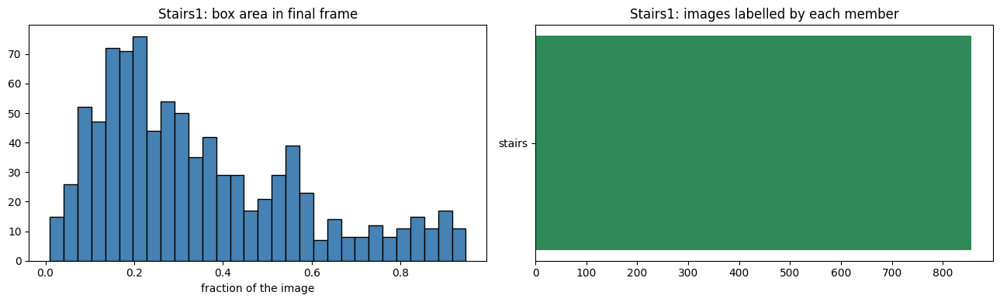

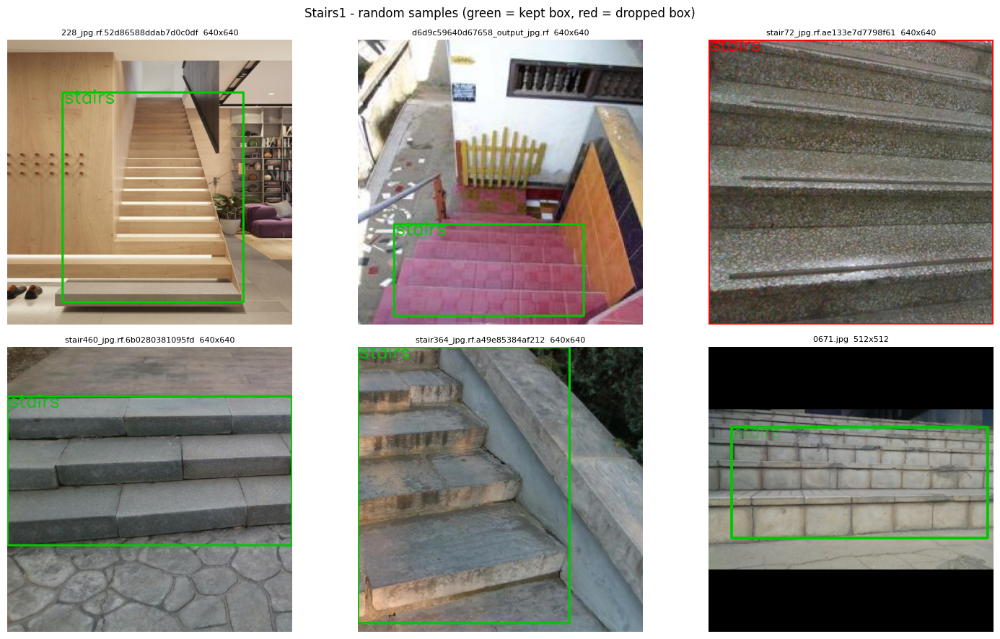

copies of the same photo (Roboflow .rf. names): 982 records -> 968 distinct photos


In [ ]:
# CELL 5a - EDA: Stairs1  (YOLO boxes; images at the folder root, labels in labels/)
recs = get_records('stairs1')   # read (or load from cache) every image + label
eda_report('Stairs1', recs)   # counts, sizes, class mapping, box statistics, sample pictures
print('copies of the same photo (Roboflow .rf. names):', len(recs), 'records ->', len({r["key"] for r in recs}), 'distinct photos')   # duplicate check



Stairs2: 505 records
status counts: {'ok': 502, 'image_without_label': 3}
image width  : 227-395 (median 227)
image height : 227-393 (median 227)
smaller than 320px on the long side (will be enlarged): 97%
with no object at all: 0

raw class name -> member -> final class        boxes
  upstair                -> stairs         -> stairs            271
  downstair              -> stairs         -> stairs            231

needed-class boxes: 502 -> 502 survive the size filters (100%)
images: 502 -> 502 keep at least one box
box area (fraction of the 320x320 frame): median 0.200, 10th pct 0.103, 90th pct 0.351

member        boxes   kept   images labelled by it
  stairs             502    502      502


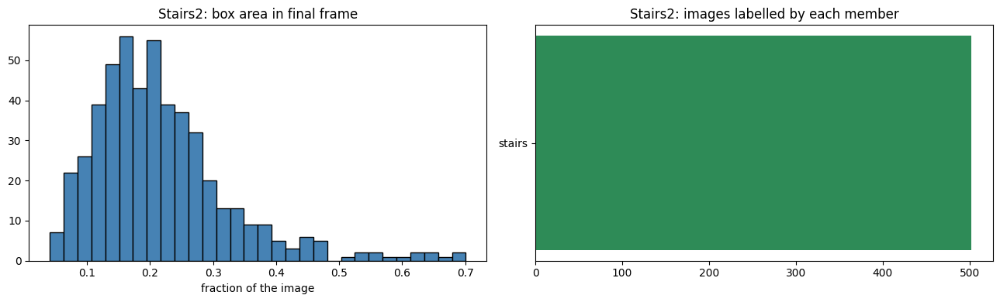

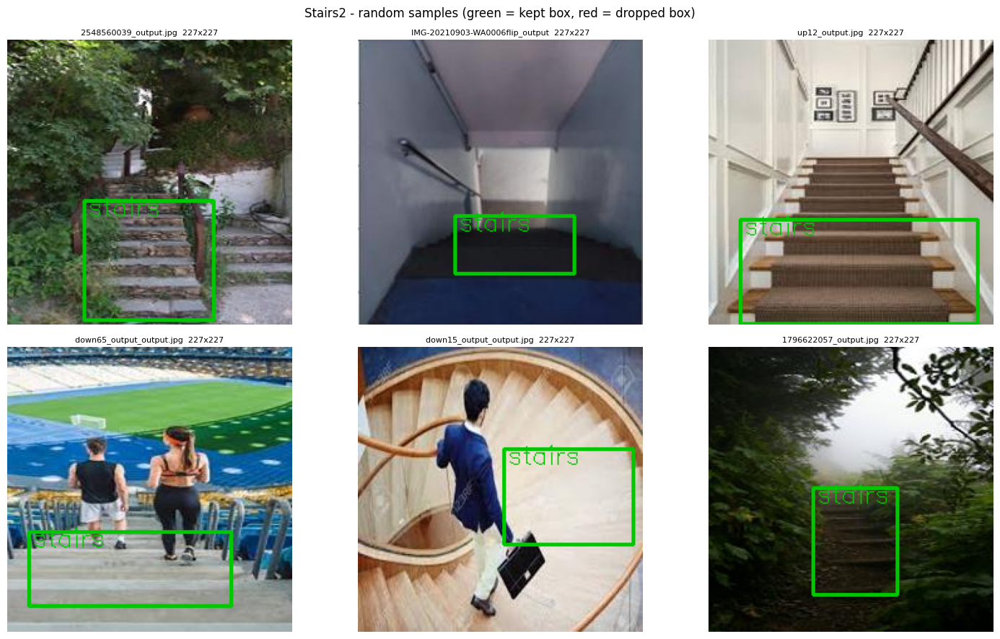

boxes rescaled because the xml size differed from the image: 0


In [ ]:
# CELL 5b - EDA: Stairs2  (Pascal-VOC xml, classes upstair/downstair, small 227x227 images)
recs = get_records('stairs2')   # read (or load from cache) every image + label
eda_report('Stairs2', recs)   # counts, sizes, class mapping, box statistics, sample pictures
print('boxes rescaled because the xml size differed from the image:', sum(1 for r in recs if r['note'] == 'rescaled'))   # how many labels needed rescaling


In [ ]:
# CELL 5c - EDA: Pothhole1 / PothRGBD  (YOLO polygons -> we use the tight box around each polygon; depths/ is ignored)
recs = get_records('pothole1')   # read (or load from cache) every image + label
eda_report('Pothhole1', recs)   # counts, sizes, class mapping, box statistics, sample pictures
sess = Counter(session_of('pothole1', r['stem']) for r in recs)   # images per capture session (date + hour)
print('capture sessions:', len(sess), '| biggest sessions:', sess.most_common(5))   # sessions must stay in one split



Pothole2: 666 records
status counts: {'ok': 665, 'image_without_label': 1}
image width  : 300-600 (median 400)
image height : 140-533 (median 300)
smaller than 320px on the long side (will be enlarged): 1%
with no object at all: 0

raw class name -> member -> final class        boxes
  pothole                -> pothole        -> pothole         1,740

needed-class boxes: 1,740 -> 1,477 survive the size filters (85%)
images: 665 -> 662 keep at least one box
box area (fraction of the 320x320 frame): median 0.025, 10th pct 0.005, 90th pct 0.154

member        boxes   kept   images labelled by it
  pothole          1,740  1,477      662


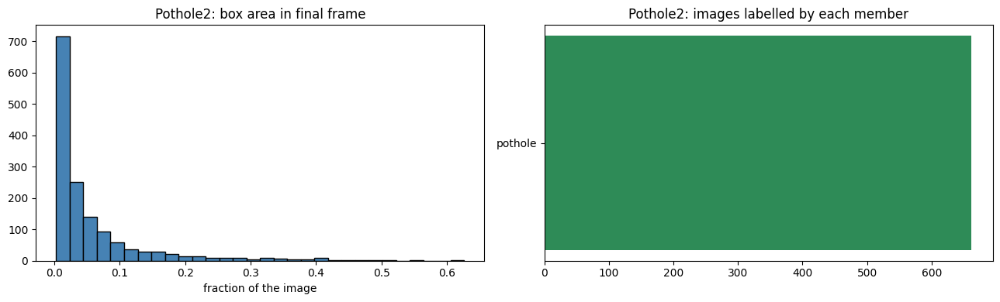

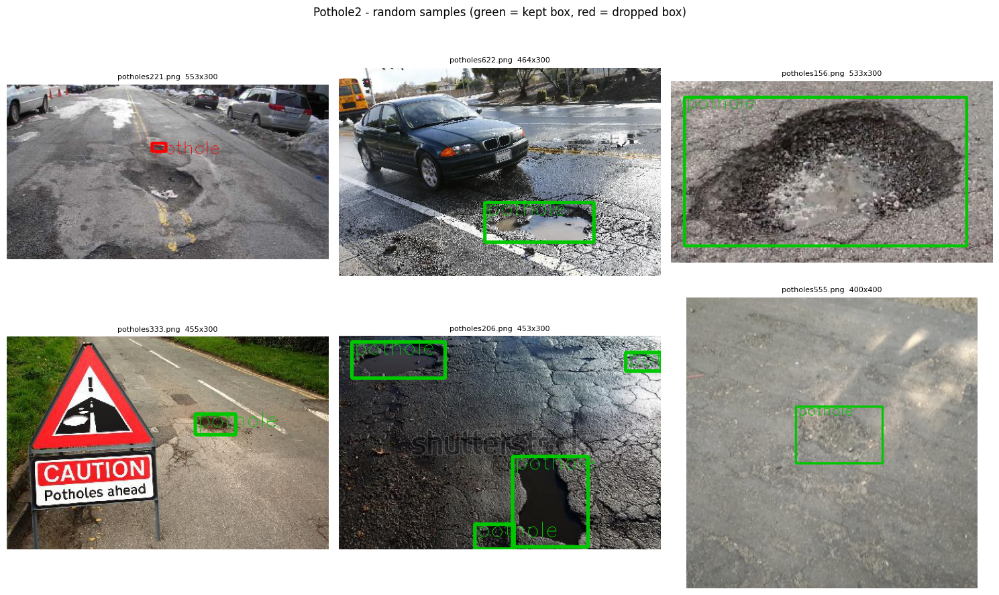

boxes rescaled because the xml size differed from the image: 0


In [ ]:
# CELL 5d - EDA: Pothole2  (Pascal-VOC xml, class pothole, PNG images of different sizes)
recs = get_records('pothole2')   # read (or load from cache) every image + label
eda_report('Pothole2', recs)   # counts, sizes, class mapping, box statistics, sample pictures
print('boxes rescaled because the xml size differed from the image:', sum(1 for r in recs if r['note'] == 'rescaled'))   # how many labels needed rescaling



Crosswalk: 3,434 records
status counts: {'ok': 3434}
image width  : 1280-1280 (median 1280)
image height : 720-720 (median 720)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 0

raw class name -> member -> final class        boxes
  id0                    -> crosswalk      -> crosswalk       3,157
  id1                    -> None           -> (ignored)         599

needed-class boxes: 3,157 -> 2,846 survive the size filters (90%)
images: 3,434 -> 2,628 keep at least one box
box area (fraction of the 320x320 frame): median 0.051, 10th pct 0.004, 90th pct 0.147

member        boxes   kept   images labelled by it
  crosswalk        3,157  2,846    2,628


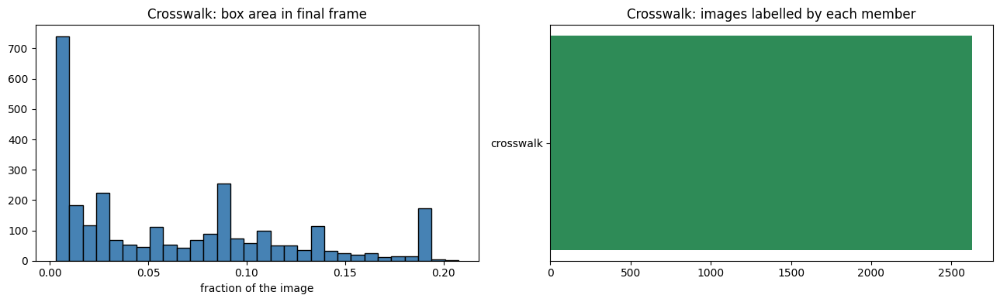

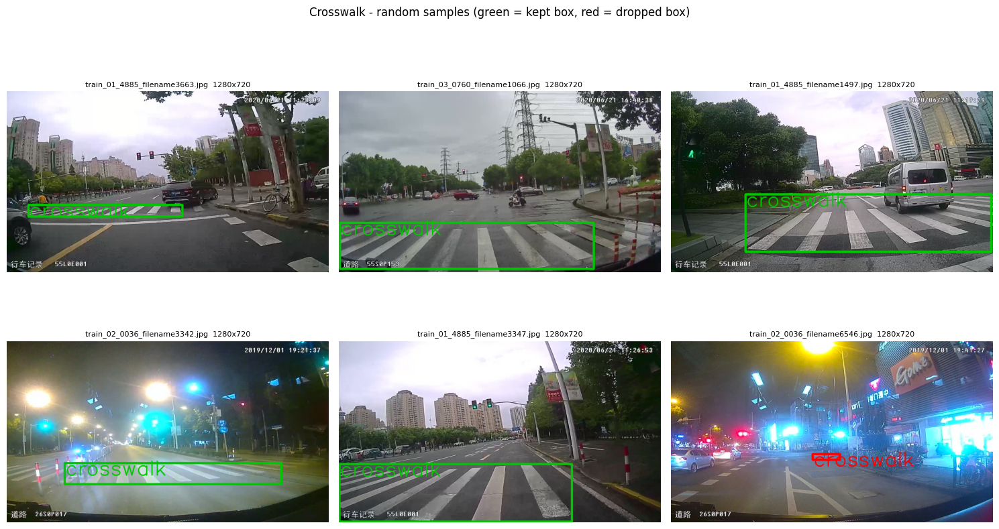

videos: {'01_4885': 756, '02_0036': 1982, '03_0760': 696}
scene blocks of 25 neighbouring frames: 276 (each block is kept inside ONE split)


In [ ]:
# CELL 5e - EDA: Crosswalk / CDSet  (YOLO boxes; id0 = crosswalk is used, id1 = guide arrows is ignored)
recs = get_records('crosswalk')   # read (or load from cache) train + test images and labels together
eda_report('Crosswalk', recs)   # counts, sizes, class mapping, box statistics, sample pictures
blocks = Counter(session_of('crosswalk', r['stem']) for r in recs)   # frames per scene block
videos = Counter(r['stem'].split('_filename')[0] for r in recs)   # frames per source video
print('videos:', dict(videos))   # the video ids found in the file names
print(f'scene blocks of {CW_BLOCK} neighbouring frames:', len(blocks), '(each block is kept inside ONE split)')   # leakage control


classification images: 1206 Counter({'ok': 1206})
crop match score: min 1.000, median 1.000
detection images: 240 Counter({'ok': 240})
door pixel share per mask: median 0.235, max 0.822
If the median share is above ~0.6, DOOR_MASK_VALUE in cell 0 is probably the wrong value (set it to 2).

Doors: 1,446 records
status counts: {'ok': 1446}
image width  : 480-480 (median 480)
image height : 640-640 (median 640)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 0

raw class name -> member -> final class        boxes
  door                   -> door           -> door            1,506

needed-class boxes: 1,506 -> 1,506 survive the size filters (100%)
images: 1,446 -> 1,446 keep at least one box
box area (fraction of the 320x320 frame): median 0.347, 10th pct 0.211, 90th pct 0.483

member        boxes   kept   images labelled by it
  door             1,506  1,506    1,446


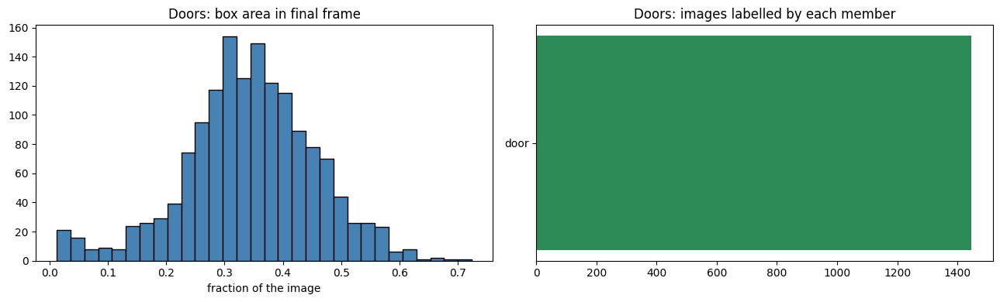

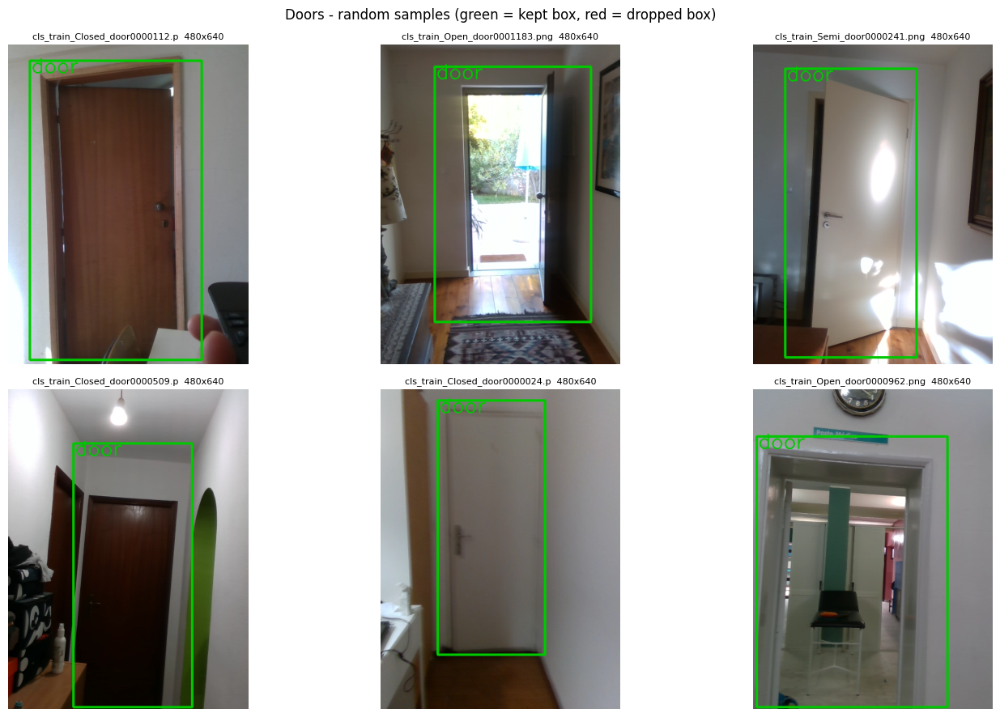

In [ ]:
# CELL 5f - EDA: Doors  (no box labels: boxes are recovered from the crops and from the masks)
recs = get_records('doors')   # read (or load from cache) every image; template-matches crops and reads masks
cls = [r for r in recs if r['note'].startswith('cls')]   # door-classification images
det = [r for r in recs if r['note'].startswith('det')]   # door-detection (mask) images
print('classification images:', len(cls), Counter(r['status'] for r in cls))   # how many boxes were recovered
scores = [float(r['note'].split('=')[1]) for r in cls if 'score=' in r['note']]   # template-match scores
print('crop match score: min %.3f, median %.3f' % (min(scores), float(np.median(scores))) if scores else 'no scores')   # ~1.0 = crop found exactly
print('detection images:', len(det), Counter(r['status'] for r in det))   # how many masks gave boxes
shares = [float(r['note'].split('=')[1]) for r in det if 'door_share=' in r['note']]   # share of door pixels per mask
print('door pixel share per mask: median %.3f, max %.3f' % (float(np.median(shares)), max(shares)) if shares else 'no masks')   # sanity check
print('If the median share is above ~0.6, DOOR_MASK_VALUE in cell 0 is probably the wrong value (set it to 2).')   # warning
eda_report('Doors', recs)   # counts, sizes, class mapping, box statistics, sample pictures



Outdoor-26classes: 32,963 records
status counts: {'ok': 32963}
image width  : 300-300 (median 300)
image height : 300-300 (median 300)
smaller than 320px on the long side (will be enlarged): 100%
with no object at all: 0

raw class name -> member -> final class        boxes
  Person                 -> person         -> person          7,369
  traffic_cone           -> traffic cone   -> object          6,152
  car                    -> car            -> car             4,734
  crosswalk              -> crosswalk      -> crosswalk       3,525
  Bushes                 -> bushes         -> vegetation      3,193
  red_light              -> traffic light  -> traffic light    3,058
  green_light            -> traffic light  -> traffic light    2,956
  bicycle                -> bicycle        -> bicycle         2,913
  elevator               -> elevator       -> door            2,910
  Bus                    -> bus            -> bus             2,679
  tree                   -> tree          

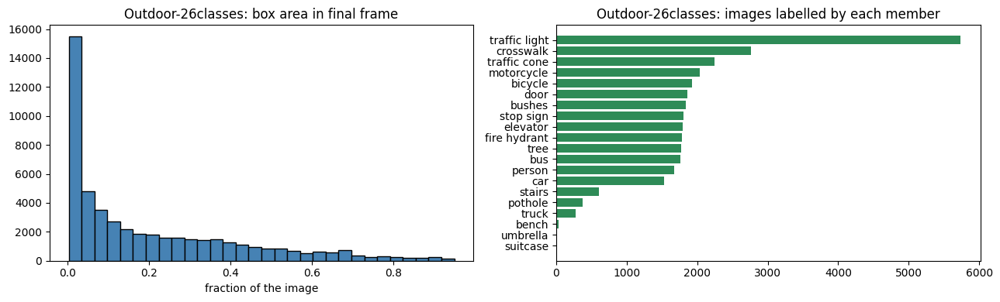

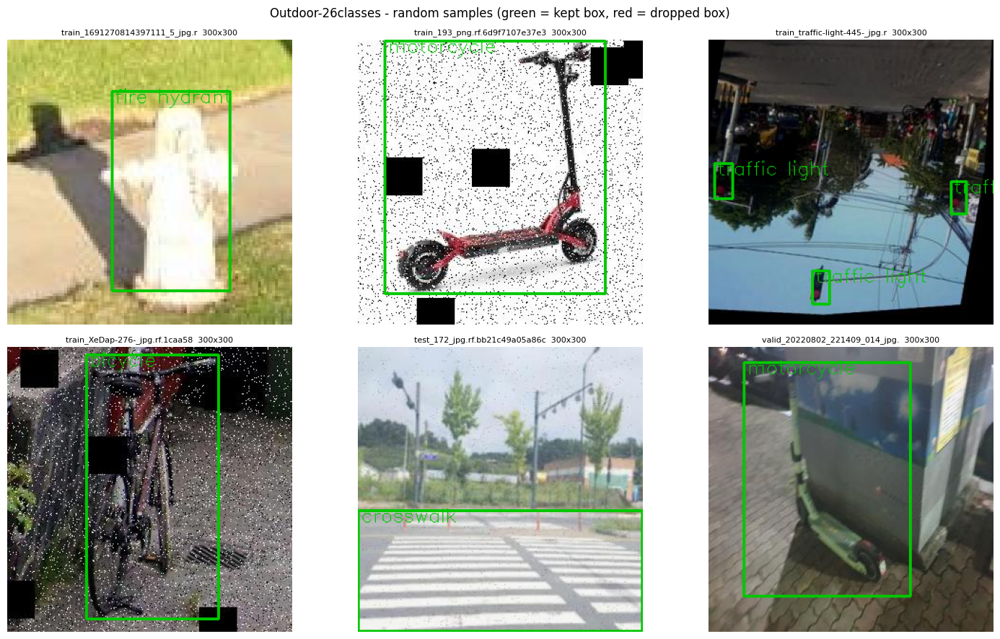

32,963 records are only 10,464 distinct photos (Roboflow augmented copies share a key)
photos found in more than one Roboflow split (a leak in the original split): 958


In [ ]:
# CELL 5g - EDA: 26classes / outdoor (Roboflow COCO json). Only images holding classes we need are analysed.
recs = get_records('outdoor')   # read (or load from cache) the annotations of train/valid/test
eda_report('Outdoor-26classes', recs)   # counts, sizes, class mapping, box statistics, sample pictures
splits_of = defaultdict(set)   # photo key -> Roboflow splits it appears in
for r in recs:   # every record
    splits_of[r['key']].add(r['note'])   # note holds the Roboflow split name
print(f'{len(recs):,} records are only {len(splits_of):,} distinct photos (Roboflow augmented copies share a key)')   # real size of the set
print('photos found in more than one Roboflow split (a leak in the original split):', sum(1 for s in splits_of.values() if len(s) > 1))   # count them



COCO: 111,785 records
status counts: {'ok': 111785}
image width  : 59-640 (median 640)
image height : 51-640 (median 480)
smaller than 320px on the long side (will be enlarged): 0%
with no object at all: 0

raw class name -> member -> final class        boxes
  person                 -> person         -> person        268,030
  car                    -> car            -> car            45,451
  chair                  -> chair          -> chair          39,844
  dining table           -> table          -> table          16,390
  traffic light          -> traffic light  -> traffic light   13,476
  handbag                -> handbag        -> object         12,882
  umbrella               -> umbrella       -> object         11,672
  bird                   -> bird           -> bird           10,969
  truck                  -> truck          -> truck          10,384
  bench                  -> bench          -> bench          10,231
  sheep                  -> sheep          -> animal      

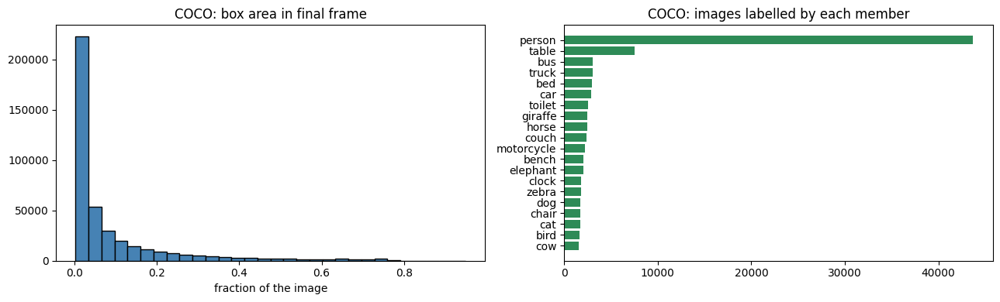

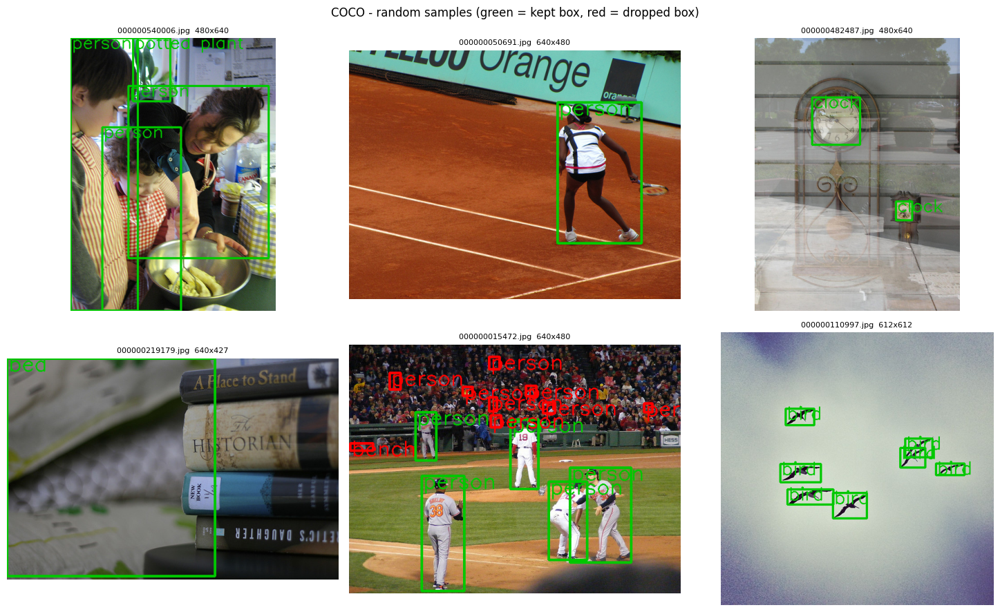

In [ ]:
# CELL 5h - EDA: COCO 2017  (train2017 + val2017). Only images holding classes we need are analysed.
recs = get_records('coco')   # read (or load from cache) the annotations; first run reads a 470 MB json
eda_report('COCO', recs)   # counts, sizes, class mapping, box statistics, sample pictures


### Combined EDA
Merges every dataset, removes duplicate photos (file-name key + perceptual hash) and shows how many independent photos each class has against the target.

  stairs1   :     856 usable images
  stairs2   :     502 usable images
  pothole1  :     996 usable images
  pothole2  :     662 usable images
  crosswalk :   2,628 usable images
  doors     :   1,446 usable images
  outdoor   :  31,849 usable images
  coco      : 107,915 usable images

Images skipped (dataset, reason): count
  coco       no valid box after filters          3,870
  outdoor    no valid box after filters          1,114
  crosswalk  no valid box after filters          806
  stairs1    no valid box after filters          80
  stairs1    label_without_image                 23
  stairs1    image_without_label                 23
  pothole1   no valid box after filters          4
  stairs2    image_without_label                 3
  pothole2   no valid box after filters          3
  pothole2   image_without_label                 1

Removing duplicate photos (this hashes about 15,000 images; the first run takes a while) ...
146,854 usable images -> 122,192 independent photos

c

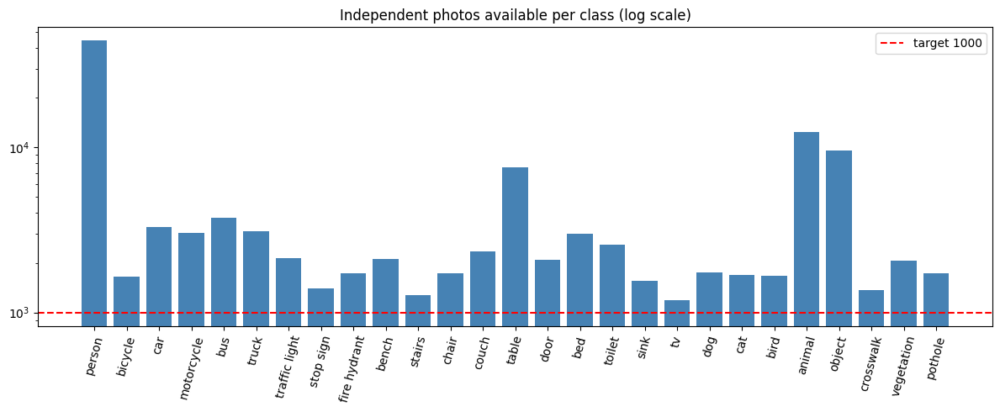

In [ ]:
# CELL 6 - COMBINED EDA: merge all datasets, remove duplicate photos, and see how many images each class can really supply.
def collect_all():   # candidates from every dataset
    cands, skipped = [], Counter()   # results
    for src in LOADERS:   # each dataset in turn
        c, s = make_candidates(get_records(src))   # records -> usable candidates
        print(f'  {src:10s}: {len(c):7,d} usable images')   # per-dataset count
        cands += c   # add to the pool
        skipped += s   # add the skip reasons
    return cands, skipped   # everything together

def dedupe_photos(cands):   # keep ONE image per photo: same file-name key OR near-identical pixels (non-COCO sets)
    by_key = defaultdict(list)   # photo key -> its copies
    for c in cands:   # every candidate
        by_key[c['key']].append(c)   # group copies of the same photo
    best = {k: max(v, key=lambda c: (len(c['boxes']), c['path'])) for k, v in by_key.items()}   # richest copy of each photo
    uf = UnionFind()   # will link photos that look identical
    for k in best:   # register every photo key
        uf.find(k)   # each starts alone
    nc = [k for k in best if best[k]['src'] != 'coco']   # COCO photos are distinct by design: hash only the others
    ph = phash_many([best[k]['path'] for k in nc])   # perceptual hash of each
    okk = [k for k in nc if ph[best[k]['path']] is not None]   # photos that could be read
    for a, b in near_dup_pairs([ph[best[k]['path']] for k in okk]):   # pairs of near-identical pictures
        uf.union(okk[a], okk[b])   # same photo found under different names
    comps = defaultdict(list)   # component root -> photo keys
    for k in best:   # every photo key
        comps[uf.find(k)].append(k)   # collect by component
    reps = []   # one representative per photo
    for root, ks in comps.items():   # each component
        rep = dict(max((best[k] for k in ks), key=lambda c: (len(c['boxes']), c['src'] != 'coco', c['path'])))   # prefer more boxes, then non-COCO
        rep['photo'] = root   # id of the photo
        rep['group'] = rep['session'] or f'p:{root}'   # split group: the scene if known, else the photo itself
        reps.append(rep)   # keep it
    return reps   # independent photos

print('Collecting candidates from all datasets ...')   # progress message
ALL, SKIPPED = collect_all()   # build every candidate
print('\nImages skipped (dataset, reason): count')   # header
for k, v in sorted(SKIPPED.items(), key=lambda kv: -kv[1])[:25]:   # the 25 most common reasons
    print(f'  {k[0]:10s} {k[1]:35s} {v:,}')   # one line each
print('\nRemoving duplicate photos (this hashes about 15,000 images; the first run takes a while) ...')   # progress message
REPS = dedupe_photos(ALL)   # independent photos
print(f'{len(ALL):,} usable images -> {len(REPS):,} independent photos')   # how much duplication there was

print(f"\n{'class':13s} {'images':>8s} {'photos':>8s} {'from COCO':>10s} {'other':>7s}   vs {TOTAL_PER_CLASS} needed")   # table header
tab = []   # rows for the chart
for cid, cname in enumerate(CLASS_LIST):   # every final class
    n_all = sum(1 for c in ALL if c['cls'] == cid)   # candidates before de-duplication
    mine = [r for r in REPS if r['cls'] == cid]   # independent photos labelled with this class
    co = sum(1 for r in mine if r['src'] == 'coco')   # of which from COCO
    flag = 'ok' if len(mine) >= TOTAL_PER_CLASS else f'SHORT by {TOTAL_PER_CLASS - len(mine):,}'   # enough or not
    print(f'{cname:13s} {n_all:8,d} {len(mine):8,d} {co:10,d} {len(mine) - co:7,d}   {flag}')   # one row per class
    tab.append((cname, len(mine)))   # for the chart
print('\nInside the merged classes (photos per member):')   # merged-class breakdown
for cname, mem in MEMBERS.items():   # each merged class
    cnt = Counter(MEMBER_LIST[r['member']] for r in REPS if r['cls'] == CLASS_ID[cname])   # photos per member
    print(f'  {cname:11s}', {m: cnt[m] for m in mem})   # show every member
plt.figure(figsize=(12, 5))   # new figure
plt.bar([t[0] for t in tab], [t[1] for t in tab], color='steelblue')   # photos per class
plt.axhline(TOTAL_PER_CLASS, color='red', ls='--', label=f'target {TOTAL_PER_CLASS}')   # target line
plt.xticks(rotation=75)   # readable labels
plt.yscale('log')   # log scale because person is huge
plt.legend()   # show the target label
plt.title('Independent photos available per class (log scale)')   # title
save_fig('availability')   # save and show


### Viewpoint check (run before the split)
Measures what the viewpoint rules would remove, per class and per source, and shows example pictures for each rule. **Look at the pictures:** if a rule removes good photos of a class, add that class to `VP_EXEMPT` (cell 0) or remove the rule from `VP_RULES`. Classes marked SHORT or TIGHT may not reach 1000 photos after filtering.

In [ ]:
# CELL 6b - VIEWPOINT AND BLACK-BOX CHECK (run before the split and the build): how many photos each rule would remove, per class and per source, with example pictures to judge by eye.
VP_PER_SOURCE = 50   # photos checked per (class, source) pair, so small sources such as the outdoor set are sampled properly (raise it for a tighter estimate)
vp_rng = random.Random(SEED)   # repeatable sample
avail = Counter((r['cls'], r['src']) for r in REPS)   # independent photos available per (class, source)
vp_pick = []   # (class id, photo record) pairs to check
for (cid, src), n in sorted(avail.items()):   # every (class, source) pair
    mine = [r for r in REPS if r['cls'] == cid and r['src'] == src]   # its independent photos
    vp_pick += [(cid, r) for r in vp_rng.sample(mine, min(VP_PER_SOURCE, len(mine)))]   # a random sample of them

def vp_check(item):   # one (class id, record) -> (class id, record, triggered rules)
    cid, r = item   # unpack
    try:   # reading may fail on Drive
        img = read_img(r['path'])   # decode the photo
        return cid, r, (viewpoint_reasons(img, object_fill(r)) if img is not None else set())   # all rules it triggers
    except Exception:   # unreadable
        return cid, r, set()   # no verdict

t0 = time.time()   # start the clock
with ThreadPoolExecutor(WORKERS) as ex:   # read in parallel
    VP_RESULT = list(ex.map(vp_check, vp_pick))   # (class id, record, rules) for every checked photo
print(f'checked {len(VP_RESULT):,} photos in {time.time() - t0:.0f} s')   # how long it took

def enforced(cid):   # rules in force for one class
    return rules_for(cid)   # the rules in force for this class (global rules minus exemptions, sky only for some classes)

def class_rate(cid, test):   # share of a class's photos that satisfy test(rules); sources are weighted by how many photos they really supply
    tot, acc = 0, 0.0   # photos available / weighted rate
    for (c, src), n in avail.items():   # every source of this class
        if c != cid:   # another class
            continue   # skip it
        rs = [rules for cc, r, rules in VP_RESULT if cc == cid and r['src'] == src]   # the sample of this (class, source)
        acc += n * (sum(1 for rules in rs if test(rules)) / max(len(rs), 1))   # rate x photos available
        tot += n   # photos available
    return acc / max(tot, 1)   # weighted share

ALL_RULES = ['aerial', 'closeup', 'studio', 'blackbox', 'sky', 'upward', 'tilt', 'blurry', 'uniform']   # every rule that exists
print(f"\n{'class':13s}{'REMOVED':>9s}   " + ''.join(f'{r:>9s}' for r in ALL_RULES) + '   photos left vs target')   # header (percent of the class's photos per rule)
print('(rules that are switched off, or exempt for that class, are shown for information only; REMOVED counts only the rules in force)')   # explanation
for cid, cname in enumerate(CLASS_LIST):   # every class
    gone = class_rate(cid, lambda rules, cid=cid: bool(rules & enforced(cid)))   # share removed by the rules in force
    n_av = sum(n for (c, _), n in avail.items() if c == cid)   # independent photos available for this class
    left = n_av * (1 - gone)   # estimate of what remains
    flag = 'ok' if left >= TOTAL_PER_CLASS * 1.2 else ('TIGHT' if left >= TOTAL_PER_CLASS else 'SHORT')   # enough photos left for the 1000 target?
    print(f'{cname:13s}{gone * 100:8.1f}%   ' + ''.join(f'{class_rate(cid, lambda rules, k=k: k in rules) * 100:8.1f}%' for k in ALL_RULES) + f'   {left:8,.0f} vs {TOTAL_PER_CLASS}  {flag}')   # one row per class

print('\nper source (sample): share removed by the rules in force, and share with black boxes (all classes, exemptions ignored):')   # second table
for src in sorted({r['src'] for _, r, _ in VP_RESULT}):   # every dataset
    rs = [(c, rules) for c, r, rules in VP_RESULT if r['src'] == src]   # its checked photos
    print(f"  {src:10s} {len(rs):5d} checked | removed {sum(1 for c, rules in rs if rules & enforced(c)) / max(len(rs), 1) * 100:5.1f}% | black boxes {sum(1 for c, rules in rs if 'blackbox' in rules) / max(len(rs), 1) * 100:5.1f}% | aerial {sum(1 for c, rules in rs if 'aerial' in rules) / max(len(rs), 1) * 100:5.1f}% | closeup {sum(1 for c, rules in rs if 'closeup' in rules) / max(len(rs), 1) * 100:5.1f}% | studio {sum(1 for c, rules in rs if 'studio' in rules) / max(len(rs), 1) * 100:5.1f}%")   # one row per source

for rule in sorted(VP_RULES):   # example pictures for every rule in force
    hits = [(c, r) for c, r, rules in VP_RESULT if rule in rules and rule in enforced(c)]   # photos removed by this rule
    show = vp_rng.sample(hits, min(8, len(hits)))   # up to 8 random ones
    if not show:   # none found
        print(f'\nrule {rule}: no photos removed in the sample')   # say so
        continue   # next rule
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))   # a 2 x 4 grid
    for ax in axes.ravel():   # start with empty cells
        ax.axis('off')   # hide the axes
    for ax, (c, r) in zip(axes.ravel(), show):   # one example per cell
        small = vp_small(read_img(r['path']))   # the photo as the tests see it
        if rule == 'blackbox':   # outline the black boxes that were found
            for x, y, bw, bh in black_boxes(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)):   # each box
                cv2.rectangle(small, (x, y), (x + bw, y + bh), (0, 0, 255), 3)   # red outline
        ax.imshow(cv2.cvtColor(small, cv2.COLOR_BGR2RGB))   # the photo
        ax.set_title(f"{CLASS_LIST[c]} ({r['src']})", fontsize=10)   # its class and source
    fig.suptitle(f'rule "{rule}" would REMOVE these ({len(hits)} of {len(VP_RESULT)} checked): are they really unsuitable?', fontsize=13)   # what to judge
    plt.tight_layout(); save_fig(f'viewpoint_{rule}')   # save and show


### Extra EDA - labels and geometry (all photos)
No pixels are read here, so it is fast. It shows: resolution and grey padding per source, photos per class by source, how many objects each photo has, **how ambiguous the label is** (label = class of the largest box, so photos where another class is almost as big are risky), which classes appear together, and the size, shape and position of the labelled object per class.

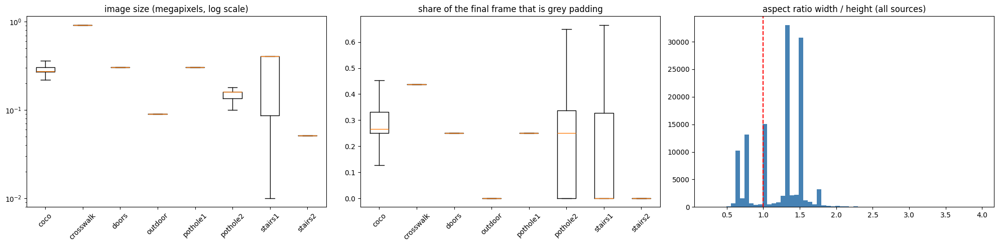

median padding share per source: {'coco': 0.27, 'crosswalk': 0.44, 'doors': 0.25, 'outdoor': 0.0, 'pothole1': 0.25, 'pothole2': 0.25, 'stairs1': 0.0, 'stairs2': 0.0}


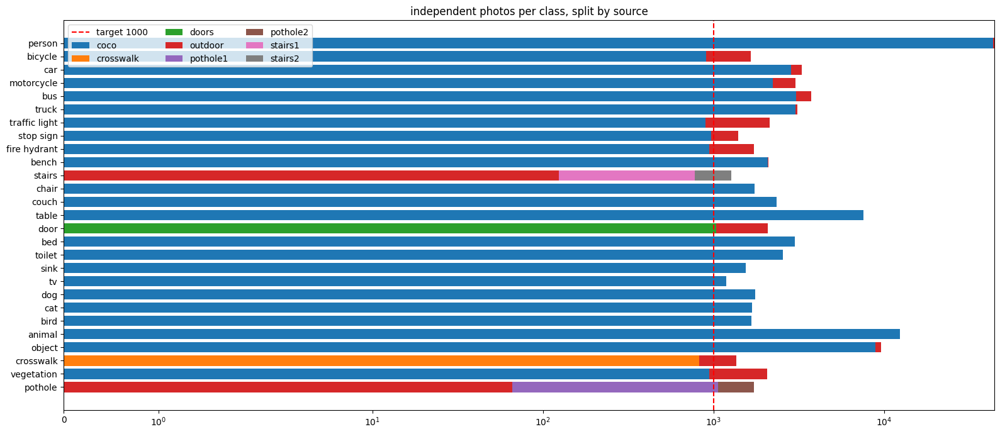

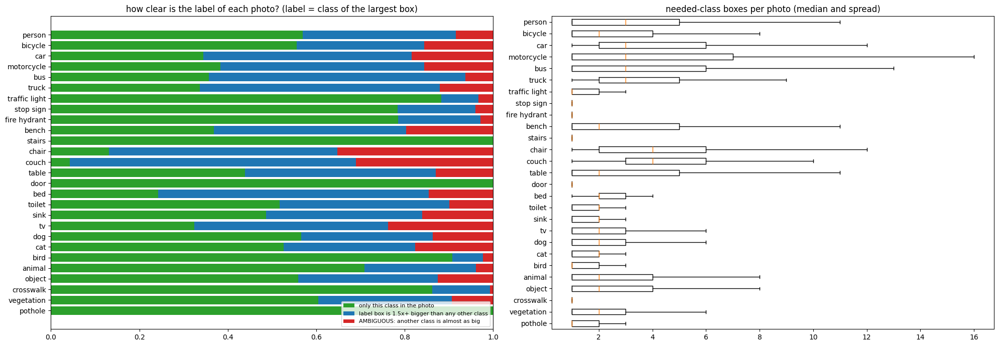

most ambiguous classes (share of photos where another class is almost as big as the label box):
  chair=35%   couch=31%   tv=24%   bench=20%   car=18%   cat=18%   sink=16%   bicycle=16%   motorcycle=16%   bed=15%


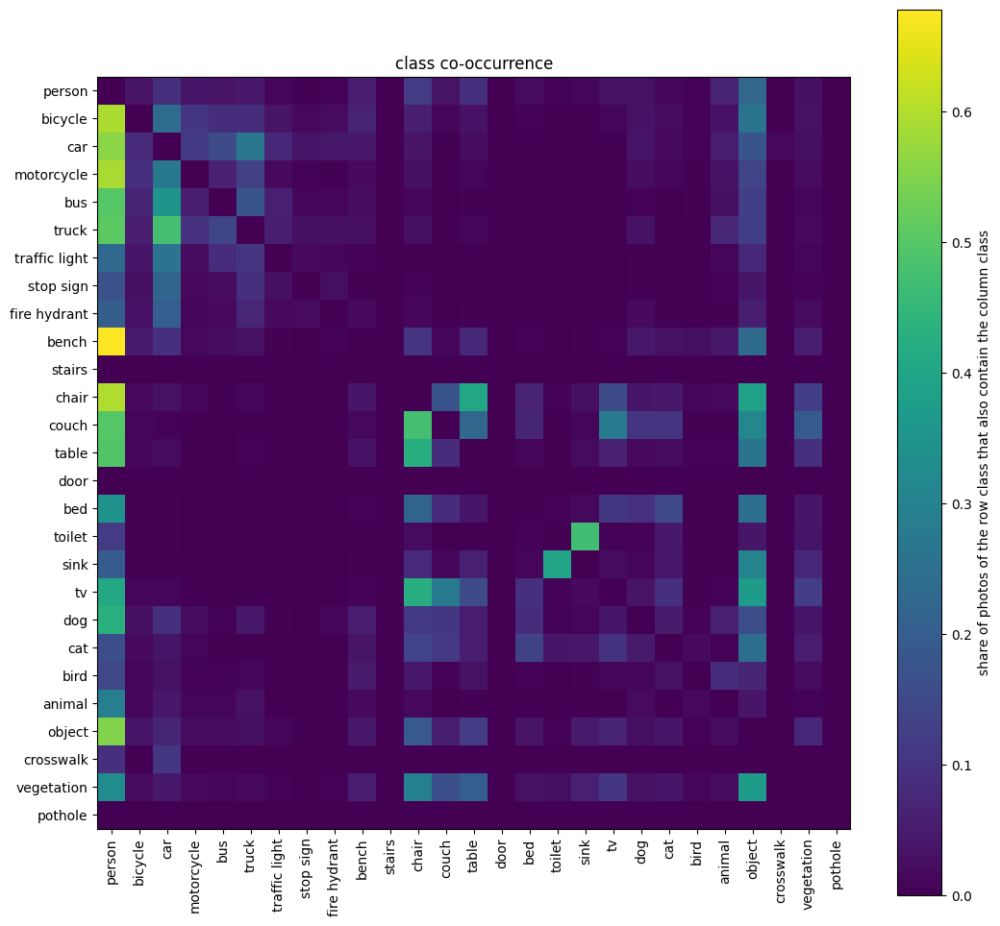

classes that most often share a photo (row -> column, share): bench -> person 68%; chair -> person 60%; bicycle -> person 60%; motorcycle -> person 59%; car -> person 56%; object -> person 55%; truck -> person 51%; couch -> person 50%; bus -> person 50%; table -> person 49%; truck -> car 48%; couch -> chair 48%


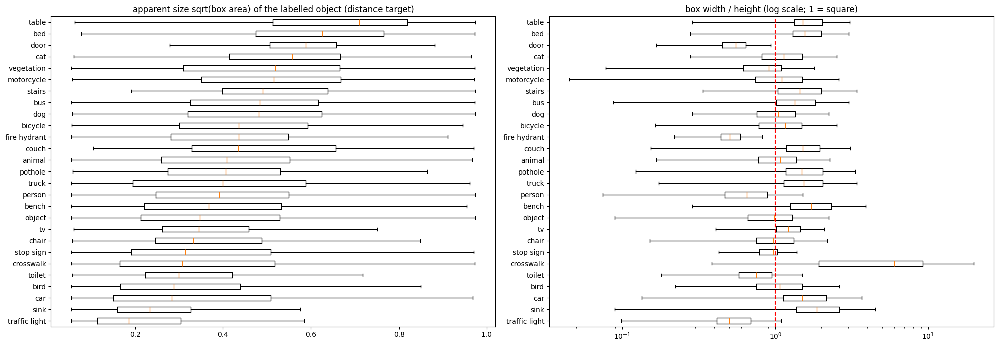

share of photos where the labelled object is tiny (size < 0.10) or fills the frame (size > 0.85):
  person: 5% / 1%   bicycle: 2% / 2%   car: 12% / 3%   motorcycle: 1% / 3%   bus: 2% / 4%   truck: 9% / 2%   traffic light: 19% / 0%   stop sign: 8% / 3%   fire hydrant: 2% / 0%   bench: 6% / 1%   stairs: 0% / 7%   chair: 3% / 3%   couch: 0% / 6%   table: 0% / 20%   door: 0% / 2%   bed: 0% / 9%   toilet: 1% / 0%   sink: 7% / 1%   tv: 1% / 1%   dog: 3% / 1%   cat: 1% / 2%   bird: 10% / 0%   animal: 4% / 1%   object: 7% / 2%   crosswalk: 8% / 1%   vegetation: 2% / 6%   pothole: 1% / 0%


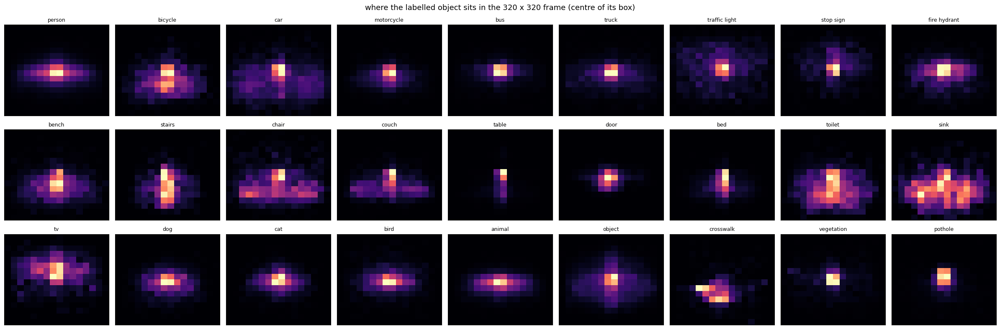

In [ ]:
# CELL 6c - EXTRA EDA, PART 1 (labels and geometry of ALL independent photos, no pixels read): resolution, padding, objects per photo, label ambiguity, co-occurrence, object size / shape / position per class.
SRC_LIST = sorted({r['src'] for r in REPS})   # datasets present
pcs = lambda a, q: float(np.percentile(a, q)) if len(a) else float('nan')   # percentile that tolerates an empty list
prim = {id(r): primary_box(r['boxes']) for r in REPS}   # the box that decides each photo's label

def boxes(ax, data, names, horizontal=False):   # a box plot that works on every matplotlib version
    try:   # newer matplotlib
        ax.boxplot(data, orientation='horizontal' if horizontal else 'vertical', showfliers=False)   # draw the boxes
    except TypeError:   # older matplotlib
        ax.boxplot(data, vert=not horizontal, showfliers=False)   # draw the boxes
    ticks = range(1, len(names) + 1)   # box positions
    (ax.set_yticks if horizontal else ax.set_xticks)(list(ticks)); (ax.set_yticklabels if horizontal else ax.set_xticklabels)(names)   # name every box

# ---- 1. resolution and letterbox padding per source ----
mp = {s: [r['w'] * r['h'] / 1e6 for r in REPS if r['src'] == s] for s in SRC_LIST}   # megapixels per source
pad = {s: [1 - (lambda p: p[3] * p[4])(letterbox_params(r['w'], r['h'])) / SIZE ** 2 for r in REPS if r['src'] == s] for s in SRC_LIST}   # share of the 320 x 320 frame that is grey padding
fig, ax = plt.subplots(1, 3, figsize=(20, 5))   # three charts
boxes(ax[0], [mp[s] for s in SRC_LIST], SRC_LIST); ax[0].set_yscale('log'); ax[0].set_title('image size (megapixels, log scale)')   # resolution per source
boxes(ax[1], [pad[s] for s in SRC_LIST], SRC_LIST); ax[1].set_title('share of the final frame that is grey padding')   # padding per source
ax[2].hist([r['w'] / r['h'] for r in REPS if r['w'] / r['h'] < 4], bins=60, color='steelblue'); ax[2].set_title('aspect ratio width / height (all sources)'); ax[2].axvline(1, color='red', linestyle='--')   # aspect ratio, 1 = square
for a_ in ax[:2]:   # rotate long names
    a_.tick_params(axis='x', rotation=45)   # readable labels
plt.tight_layout(); save_fig('extra_resolution_padding')   # save and show
print('median padding share per source:', {s: round(pcs(pad[s], 50), 2) for s in SRC_LIST})   # how much of the frame is wasted on padding

# ---- 2. photos per class by source ----
cnt = np.array([[sum(1 for r in REPS if r['cls'] == c and r['src'] == s) for s in SRC_LIST] for c in range(NC)])   # class x source counts
fig, ax = plt.subplots(figsize=(16, 7))   # one wide chart
left = np.zeros(NC)   # running left edge of the stacked bars
for j, s in enumerate(SRC_LIST):   # one colour per source
    ax.barh(range(NC), cnt[:, j], left=left, label=s)   # stacked bar
    left += cnt[:, j]   # move the edge
ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_LIST); ax.invert_yaxis(); ax.axvline(TOTAL_PER_CLASS, color='red', linestyle='--', label=f'target {TOTAL_PER_CLASS}')   # class names and target line
ax.set_xscale('symlog'); ax.set_title('independent photos per class, split by source'); ax.legend(ncol=3)   # log-ish scale because person is huge
save_fig('extra_photos_by_source')   # save and show

# ---- 3. objects per photo and label ambiguity ----
def other_area(r):   # area of the largest box of a DIFFERENT class in the same photo (0 when there is none)
    p = prim[id(r)]   # the labelling box
    return max([b[3] * b[4] for b in r['boxes'] if b[0] != p[0]] or [0.0])   # largest foreign box

n_boxes = {c: [len(r['boxes']) for r in REPS if r['cls'] == c] for c in range(NC)}   # needed-class boxes per photo, per class
ratio = {c: [(prim[id(r)][3] * prim[id(r)][4]) / max(other_area(r), 1e-9) for r in REPS if r['cls'] == c] for c in range(NC)}   # how much bigger the label box is than the biggest box of another class
kind = np.array([[np.mean([x >= 1e6 for x in ratio[c]]), np.mean([1.5 <= x < 1e6 for x in ratio[c]]), np.mean([x < 1.5 for x in ratio[c]])] for c in range(NC)])   # single-class / clear winner / ambiguous
fig, ax = plt.subplots(1, 2, figsize=(20, 7))   # two charts
ax[0].barh(range(NC), kind[:, 0], label='only this class in the photo', color='tab:green')   # share of photos with a single class
ax[0].barh(range(NC), kind[:, 1], left=kind[:, 0], label='label box is 1.5x+ bigger than any other class', color='tab:blue')   # clear winner
ax[0].barh(range(NC), kind[:, 2], left=kind[:, 0] + kind[:, 1], label='AMBIGUOUS: another class is almost as big', color='tab:red')   # ambiguous
ax[0].set_yticks(range(NC)); ax[0].set_yticklabels(CLASS_LIST); ax[0].invert_yaxis(); ax[0].set_title('how clear is the label of each photo? (label = class of the largest box)'); ax[0].legend(loc='lower right', fontsize=8)   # decorate
boxes(ax[1], [n_boxes[c] for c in range(NC)], CLASS_LIST, horizontal=True); ax[1].invert_yaxis(); ax[1].set_title('needed-class boxes per photo (median and spread)')   # objects per photo
save_fig('extra_label_ambiguity')   # save and show
print('most ambiguous classes (share of photos where another class is almost as big as the label box):')   # explanation
print('  ' + '   '.join(f'{CLASS_LIST[c]}={kind[c, 2] * 100:.0f}%' for c in np.argsort(-kind[:, 2])[:10]))   # top ten

# ---- 4. which classes appear together ----
co = np.zeros((NC, NC))   # co[i, j] = photos containing class i that also contain class j
for r in REPS:   # every photo
    present = sorted({b[0] for b in r['boxes']})   # classes that appear in it
    for i in present:   # each of them
        for j in present:   # paired with each of them
            co[i, j] += 1   # count the pair
cond = co / np.maximum(np.diag(co)[:, None], 1)   # P(class j appears | class i appears)
np.fill_diagonal(cond, 0)   # ignore a class with itself
fig, ax = plt.subplots(figsize=(11, 10))   # one square chart
im = ax.imshow(cond, cmap='viridis'); plt.colorbar(im, ax=ax, label='share of photos of the row class that also contain the column class')   # heat map
ax.set_xticks(range(NC)); ax.set_xticklabels(CLASS_LIST, rotation=90); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASS_LIST); ax.set_title('class co-occurrence')   # labels
save_fig('extra_cooccurrence')   # save and show
pairs = sorted(((cond[i, j], CLASS_LIST[i], CLASS_LIST[j]) for i in range(NC) for j in range(NC) if i != j), reverse=True)[:12]   # strongest pairs
print('classes that most often share a photo (row -> column, share):', '; '.join(f'{a} -> {b} {v * 100:.0f}%' for v, a, b in pairs))   # print them

# ---- 5. object size, shape and position of the labelling box ----
size_t = {c: [math.sqrt(prim[id(r)][3] * prim[id(r)][4]) for r in REPS if r['cls'] == c] for c in range(NC)}   # apparent size = sqrt(box area), the target of the distance head
aspect = {c: [prim[id(r)][3] / prim[id(r)][4] for r in REPS if r['cls'] == c] for c in range(NC)}   # box width / height in the final frame
order = np.argsort([np.median(size_t[c]) for c in range(NC)])   # classes sorted by typical size
fig, ax = plt.subplots(1, 2, figsize=(20, 7))   # two charts
boxes(ax[0], [size_t[c] for c in order], [CLASS_LIST[c] for c in order], horizontal=True); ax[0].set_title('apparent size sqrt(box area) of the labelled object (distance target)')   # size per class
boxes(ax[1], [aspect[c] for c in order], [CLASS_LIST[c] for c in order], horizontal=True); ax[1].set_xscale('log'); ax[1].axvline(1, color='red', linestyle='--'); ax[1].set_title('box width / height (log scale; 1 = square)')   # shape per class
save_fig('extra_size_shape')   # save and show
print('share of photos where the labelled object is tiny (size < 0.10) or fills the frame (size > 0.85):')   # explanation
print('  ' + '   '.join(f'{CLASS_LIST[c]}: {np.mean(np.array(size_t[c]) < 0.10) * 100:.0f}% / {np.mean(np.array(size_t[c]) > 0.85) * 100:.0f}%' for c in range(NC)))   # per class
fig, axes = plt.subplots(3, 9, figsize=(24, 8))   # one small map per class
for c, ax in zip(range(NC), axes.ravel()):   # every class
    xs = [prim[id(r)][1] for r in REPS if r['cls'] == c]; ys = [prim[id(r)][2] for r in REPS if r['cls'] == c]   # centres of the labelled boxes
    ax.hist2d(xs, ys, bins=16, range=[[0, 1], [0, 1]], cmap='magma'); ax.invert_yaxis(); ax.set_title(CLASS_LIST[c], fontsize=9); ax.set_xticks([]); ax.set_yticks([])   # where the object sits in the frame
fig.suptitle('where the labelled object sits in the 320 x 320 frame (centre of its box)', fontsize=13)   # title
save_fig('extra_position')   # save and show


### Extra EDA - pixels (a sample)
Reads about 25 photos per (class, source) and shows brightness, contrast, sharpness, colour, the **average picture of every class**, differences between the source datasets and contact sheets (6 photos per class with the labelled box).

In [ ]:
# CELL 6d - EXTRA EDA, PART 2 (pixels of a SAMPLE of photos): brightness, contrast, sharpness, colour, the average picture of every class, and contact sheets with the labelled boxes.
PIX_PER_SOURCE = 25   # photos read per (class, source) pair
pix_rng = random.Random(SEED + 1)   # repeatable sample
pix_pick = []   # (class id, record) pairs
for (cid, src), n in sorted(Counter((r['cls'], r['src']) for r in REPS).items()):   # every (class, source) pair
    mine = [r for r in REPS if r['cls'] == cid and r['src'] == src]   # its photos
    pix_pick += [(cid, r) for r in pix_rng.sample(mine, min(PIX_PER_SOURCE, len(mine)))]   # random few

def pix_stats(item):   # one (class id, record) -> measurements and a 128 x 128 letterboxed thumbnail
    cid, r = item   # unpack
    try:   # reading may fail
        img = read_img(r['path'])   # decode the photo
        if img is None:   # unreadable
            return None   # skip
        small = vp_small(img)   # same shrink as the viewpoint tests
        g = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)   # grey copy
        hsv = cv2.cvtColor(small, cv2.COLOR_BGR2HSV)   # for the colourfulness
        thumb = cv2.resize(letterbox(img), (128, 128), interpolation=cv2.INTER_AREA)   # the picture as the model sees it, small
        return dict(cid=cid, src=r['src'], bright=float(g.mean()), contrast=float(g.std()), sharp=float(cv2.Laplacian(g, cv2.CV_64F).var()),   # lighting, contrast, detail
                    sat=float(hsv[:, :, 1].mean()), dark=float(np.mean(g < 40)), bgr=small.reshape(-1, 3).mean(0), thumb=thumb, box=prim[id(r)])   # colour, dark share, mean colour, thumbnail, labelling box
    except Exception:   # any failure
        return None   # skip

t0 = time.time()   # start the clock
with ThreadPoolExecutor(WORKERS) as ex:   # read in parallel
    PIX = [p for p in ex.map(pix_stats, pix_pick) if p is not None]   # measurements of every sampled photo
print(f'measured {len(PIX):,} photos in {time.time() - t0:.0f} s')   # how long it took

def by_class(key):   # list of one measurement per class
    return [[p[key] for p in PIX if p['cid'] == c] for c in range(NC)]   # values grouped by class

def class_box(vals, title, fname, log=False):   # a horizontal box plot per class, sorted by median
    o = np.argsort([np.median(v) if v else 0 for v in vals])   # sort classes
    fig, ax = plt.subplots(figsize=(11, 8))   # one chart
    boxes(ax, [vals[c] for c in o], [CLASS_LIST[c] for c in o], horizontal=True)   # the boxes
    if log:   # skewed values
        ax.set_xscale('log')   # log axis
    ax.set_title(title)   # title
    save_fig(fname)   # save and show

class_box(by_class('bright'), 'brightness (mean grey level 0-255): low = night / dark scenes', 'extra_brightness')   # lighting per class
class_box(by_class('contrast'), 'contrast (standard deviation of grey levels)', 'extra_contrast')   # contrast per class
class_box(by_class('sharp'), 'sharpness (variance of the Laplacian, log scale): low = blurry', 'extra_sharpness', log=True)   # detail per class
dark = {c: np.mean([p['dark'] > 0.6 for p in PIX if p['cid'] == c]) * 100 for c in range(NC)}   # share of mostly-dark photos
print('share of photos that are more than 60 percent dark pixels (night / underexposed):', '  '.join(f'{CLASS_LIST[c]}={dark[c]:.0f}%' for c in np.argsort([-dark[c] for c in range(NC)])[:8]))   # worst classes

# ---- per source: are the datasets alike? ----
fig, ax = plt.subplots(1, 2, figsize=(16, 6))   # two charts
for s in SRC_LIST:   # every dataset
    pts = [p for p in PIX if p['src'] == s]   # its sampled photos
    ax[0].scatter([p['bright'] for p in pts], [p['sharp'] for p in pts], s=8, alpha=0.5, label=s)   # brightness vs sharpness
ax[0].set_yscale('log'); ax[0].set_xlabel('brightness'); ax[0].set_ylabel('sharpness (log)'); ax[0].legend(markerscale=2); ax[0].set_title('every sampled photo, coloured by source')   # decorate
boxes(ax[1], [[p['sat'] for p in PIX if p['src'] == s] for s in SRC_LIST], SRC_LIST); ax[1].tick_params(axis='x', rotation=45); ax[1].set_title('colourfulness (mean saturation) per source')   # colour per source
save_fig('extra_sources_pixels')   # save and show
print('median brightness / sharpness per source:', {s: (round(pcs([p['bright'] for p in PIX if p['src'] == s], 50)), round(pcs([p['sharp'] for p in PIX if p['src'] == s], 50))) for s in SRC_LIST})   # numbers

# ---- mean colour and the average picture of every class ----
fig, axes = plt.subplots(3, 9, figsize=(24, 8))   # one cell per class
for c, ax in zip(range(NC), axes.ravel()):   # every class
    th = [p['thumb'] for p in PIX if p['cid'] == c]   # its thumbnails
    ax.imshow(cv2.cvtColor(np.mean(th, axis=0).astype(np.uint8), cv2.COLOR_BGR2RGB)); ax.set_title(f'{CLASS_LIST[c]} (n={len(th)})', fontsize=9); ax.axis('off')   # the average picture
fig.suptitle('average picture of every class (as the model sees it, with the grey letterbox): shows where objects usually are and how much is padding', fontsize=13)   # title
save_fig('extra_mean_images')   # save and show
fig, ax = plt.subplots(figsize=(18, 2.6))   # a strip of colour swatches
for c in range(NC):   # every class
    col = np.mean([p['bgr'] for p in PIX if p['cid'] == c], axis=0)[::-1] / 255.0   # mean colour as RGB 0-1
    ax.add_patch(plt.Rectangle((c, 0), 0.95, 1, color=np.clip(col, 0, 1)))   # one swatch
ax.set_xlim(0, NC); ax.set_ylim(0, 1); ax.set_xticks(np.arange(NC) + 0.45); ax.set_xticklabels(CLASS_LIST, rotation=90); ax.set_yticks([]); ax.set_title('mean colour of the photos of every class')   # decorate
save_fig('extra_mean_colour')   # save and show

# ---- contact sheets: 6 random photos per class with the labelling box ----
def contact_sheet(classes, name):   # a grid with one row per class
    fig, axes = plt.subplots(len(classes), 6, figsize=(16, 2.7 * len(classes)))   # rows = classes
    for row, c in zip(axes, classes):   # every class
        pool = [p for p in PIX if p['cid'] == c]   # its sampled photos
        show = pix_rng.sample(pool, min(6, len(pool)))   # six random ones
        for ax in row:   # start empty
            ax.axis('off')   # hide the axes
        for ax, p in zip(row, show):   # each photo
            th = p['thumb'].copy()   # thumbnail
            _, cx, cy, bw, bh, _ = p['box']   # the labelling box (fractions of the frame)
            cv2.rectangle(th, (int((cx - bw / 2) * 128), int((cy - bh / 2) * 128)), (int((cx + bw / 2) * 128), int((cy + bh / 2) * 128)), (0, 255, 0), 2)   # green outline
            ax.imshow(cv2.cvtColor(th, cv2.COLOR_BGR2RGB)); ax.set_title(f"{CLASS_LIST[c]} ({p['src']})", fontsize=8)   # picture and its source
    save_fig(name)   # save and show

for k in range(0, NC, 9):   # three sheets of nine classes
    contact_sheet(list(range(k, min(k + 9, NC))), f'extra_contact_sheet_{k // 9 + 1}')   # draw one sheet


## Part C - Preprocessing
### Split (no scene shared between train / val / test)

In [ ]:
# CELL 7 - SPLIT: give every scene to train / val / test so that no scene is shared between splits.
def assign_splits(reps, seed=SEED):   # decide the split of every group (scene or photo)
    rng = random.Random(seed)   # fixed random generator
    groups = defaultdict(list)   # group id -> its images
    for r in reps:   # every independent photo
        groups[r['group']].append(r)   # collect by group
    gclasses = {g: Counter(r['cls'] for r in rs) for g, rs in groups.items()}   # classes inside each group
    N = Counter(r['cls'] for r in reps)   # photos per class
    target = {s: {} for s in ('val', 'test')}   # how many photos each class should give to val and test
    for c, n in N.items():   # every class
        for s in ('val', 'test'):   # the two held-out splits
            frac = round(SPLIT_FRAC[s] * n)   # 10% of the class
            target[s][c] = max(QUOTA[s], frac) if n >= TOTAL_PER_CLASS else frac   # at least the quota when the class is big enough
    split_of, cnt = {}, {s: Counter() for s in ('val', 'test')}   # chosen splits and running counts
    for c in sorted(N, key=lambda k: N[k]):   # rarest classes first, so they get their share
        todo = sorted(g for g in groups if g not in split_of and c in gclasses[g])   # undecided groups containing this class
        rng.shuffle(todo)   # random order
        for g in todo:   # each group
            n_c = gclasses[g][c]   # how many images of class c it holds
            for s in ('test', 'val'):   # try the held-out splits first
                if cnt[s][c] < target[s][c] and cnt[s][c] + n_c <= max(1, int(target[s][c] * 1.5)):   # needs more, and does not overshoot much
                    split_of[g] = s   # assign the whole group
                    for cc, k in gclasses[g].items():   # update the counts of every class in it
                        cnt[s][cc] += k   # add them
                    break   # decided
            else:   # no held-out split took it
                split_of[g] = 'train'   # it goes to training
    for r in reps:   # write the decision into every image
        r['split'] = split_of[r['group']]   # train / val / test

assign_splits(REPS)   # run the split
print(f"{'class':13s} {'train':>7s} {'val':>6s} {'test':>6s}   train quota {QUOTA['train']}, val {QUOTA['val']}, test {QUOTA['test']}")   # header
short = []   # classes that cannot fill a quota
for cid, cname in enumerate(CLASS_LIST):   # every class
    n = {s: sum(1 for r in REPS if r['cls'] == cid and r['split'] == s) for s in ('train', 'val', 'test')}   # photos per split
    bad = [s for s in n if n[s] < QUOTA[s]]   # splits below their quota
    if bad:   # something is short
        short.append((cname, {s: QUOTA[s] - n[s] for s in bad}))   # remember by how much
    print(f"{cname:13s} {n['train']:7,d} {n['val']:6,d} {n['test']:6,d}   " + ('ok' if not bad else 'SHORT ' + str({s: QUOTA[s] - n[s] for s in bad})))   # one row per class
print('\nClasses that cannot reach the quota with the current data:', short or 'none')   # summary
grp_split = defaultdict(set)   # group -> splits (must be exactly one each)
for r in REPS:   # every image
    grp_split[r['group']].add(r['split'])   # note its split
print('groups in more than one split (must be 0):', sum(1 for s in grp_split.values() if len(s) > 1))   # leakage check


class           train    val   test   train quota 800, val 100, test 100
person         35,516  4,440  4,440   ok
bicycle         1,324    165    165   ok
car             2,636    330    330   ok
motorcycle      2,414    302    302   ok
bus             2,983    373    373   ok
truck           2,492    311    311   ok
traffic light   1,714    214    214   ok
stop sign       1,117    140    140   ok
fire hydrant    1,387    173    173   ok
bench           1,682    210    210   ok
stairs          1,020    127    127   ok
chair           1,388    174    174   ok
couch           1,877    234    234   ok
table           6,044    755    755   ok
door            1,662    211    213   ok
bed             2,403    300    300   ok
toilet          2,048    256    256   ok
sink            1,242    155    155   ok
tv                948    118    118   ok
dog             1,403    176    176   ok
cat             1,349    169    169   ok
bird            1,332    167    167   ok
animal          9,955  1,

### Build the final dataset
Writes `final_dataset/<split>/<class>/image.jpg + image.txt` on local disk. Merged classes are balanced between their members.

In [ ]:
# CELL 8 - BUILD THE FINAL DATASET: picks QUOTA images per class and split, balances the members of merged classes,
# letterboxes to 320x320, writes image + label into  final_dataset/<split>/<class>/  (resume-safe: just run it again).
class HashBank:   # remembers the hash of every accepted image so near-duplicates are never added twice (any class, any split)
    def __init__(self):   # start empty
        self.a = np.zeros(1 << 15, dtype=np.uint64)   # storage for hashes
        self.n = 0   # how many are stored
    def add(self, h):   # store one hash
        if self.n == len(self.a):   # storage full
            self.a = np.concatenate([self.a, np.zeros(len(self.a), dtype=np.uint64)])   # double it
        self.a[self.n] = np.uint64(h)   # write the hash
        self.n += 1   # one more stored
    def near(self, h):   # is there an accepted image within PHASH_T bits of h?
        return self.n > 0 and bool((popcount64(self.a[:self.n] ^ np.uint64(h)) <= PHASH_T).any())   # compare with all stored hashes

BANK = HashBank()   # shared by all splits

def prepare(c):   # decode, check, hash and letterbox one candidate -> (candidate, jpeg bytes or None, hash, reject reason)
    try:   # reading may fail
        img = read_img(c['path'])   # decode the image
    except Exception:   # Drive or file error
        return c, None, None, 'unreadable (I/O)'   # reject
    if img is None:   # decoder returned nothing
        return c, None, None, 'unreadable'   # reject
    if (img.shape[1], img.shape[0]) != (c['w'], c['h']):   # size differs from what the labels assumed
        return c, None, None, 'size mismatch'   # reject
    ok, why = quality_ok(img)   # brightness / contrast / size check
    if not ok:   # failed the quality filter
        return c, None, None, why   # reject with the reason
    if VIEWPOINT_FILTER:   # aerial / extreme close-up / studio photos are skipped (the next candidate is tried instead)
        bad = viewpoint_reject(img, c['cls'], object_fill(c))   # which rules it breaks, if any
        if bad:   # not a useful viewpoint
            return c, None, None, 'viewpoint: ' + bad   # reject with the reason
    h = phash_img(img)   # perceptual hash of the original picture
    okj, buf = cv2.imencode('.jpg', letterbox(img), [cv2.IMWRITE_JPEG_QUALITY, 95])   # letterbox + JPEG quality 95
    return (c, buf.tobytes(), h, '') if okj else (c, None, None, 'encode failed')   # return the bytes or reject

def label_text(boxes):   # YOLO label text: class cx cy w h (the member id is dropped)
    return '\n'.join(f'{b[0]} {b[1]:.6f} {b[2]:.6f} {b[3]:.6f} {b[4]:.6f}' for b in boxes)   # one line per box

def interleave(a, b):   # a0 b0 a1 b1 ... (so both lists are used evenly; the longer one fills the rest)
    out, i, j = [], 0, 0   # result and two cursors
    while i < len(a) or j < len(b):   # until both are used up
        if i < len(a):   # take from a
            out.append(a[i]); i += 1   # advance a
        if j < len(b):   # take from b
            out.append(b[j]); j += 1   # advance b
    return out   # merged order

def class_dir(split, cid):   # folder of one class in one split
    return Path(FINAL_LOCAL) / split / folder_name(CLASS_LIST[cid])   # final_dataset/<split>/<class>

def build_class(split, cid, ex):   # fill one class folder; returns (rows, rejects)
    cname, out = CLASS_LIST[cid], class_dir(split, cid)   # names and folder
    shutil.rmtree(out, ignore_errors=True)   # remove any half-finished earlier attempt
    out.mkdir(parents=True)   # fresh folder
    pool = [r for r in REPS if r['split'] == split and r['cls'] == cid]   # photos allowed in this class and split
    queues = {}   # member -> ordered candidates
    for m in MEMBERS.get(cname, [cname]):   # every member of the class
        mine = [r for r in pool if MEMBER_LIST[r['member']] == m]   # photos whose label comes from this member
        mine.sort(key=lambda r: r['stem'])   # fixed order before shuffling (reproducible)
        rr = random.Random(f'{SEED}-{split}-{m}')   # reproducible shuffle
        a = [r for r in mine if r['src'] != 'coco']   # in-domain photos from the other datasets
        b = [r for r in mine if r['src'] == 'coco']   # COCO photos
        rr.shuffle(a); rr.shuffle(b)   # random order inside each list
        queues[m] = deque(interleave(a, b))   # alternate between the two
    order = list(queues)   # fixed member order (tie-break)
    rows, got, rejects, quota = [], Counter(), Counter(), QUOTA[split]   # state
    while len(rows) < quota and any(queues.values()):   # until the quota is met or the candidates run out
        batch = []   # candidates to read in parallel
        sim = Counter(got)   # member counts as if the batch were accepted
        while len(batch) < min(48, quota - len(rows)):   # fill one batch
            live = [m for m in order if queues[m]]   # members that still have candidates
            if not live:   # nothing left anywhere
                break   # stop filling
            m = min(live, key=lambda k: sim[k])   # always take from the member with the fewest accepted -> balanced
            batch.append((m, queues[m].popleft()))   # take its next candidate
            sim[m] += 1   # count it
        for (m, c), (_, data, h, why) in zip(batch, ex.map(prepare, [c for _, c in batch])):   # read the batch in parallel
            if len(rows) >= quota:   # quota reached inside the batch
                break   # ignore the surplus
            if data is None:   # candidate was rejected
                rejects[why] += 1   # count the reason
                continue   # next one
            if BANK.near(h):   # looks like an image we already accepted (any split / class)
                rejects['near-duplicate'] += 1   # count it
                continue   # next one
            (out / f"{c['stem']}.jpg").write_bytes(data)   # write the letterboxed image
            (out / f"{c['stem']}.txt").write_text(label_text(c['boxes']))   # write its YOLO label
            BANK.add(h)   # remember its hash
            got[m] += 1   # count it for its member
            rows.append(dict(split=split, cls=cname, member=m, src=c['src'], file=f"{c['stem']}.jpg", group=c['group'], hash=str(h)))   # manifest row
    (out / '_meta.json').write_text(json.dumps(dict(rows=rows, rejects=dict(rejects), quota=quota)))   # marks the class as finished
    return rows, rejects   # results

def restore_finished():   # after a restart: reload the hashes of class folders that are already finished
    n = 0   # finished folders found
    for split in ('test', 'val', 'train'):   # every split
        for cid in range(NC):   # every class
            mp = class_dir(split, cid) / '_meta.json'   # the finished-marker
            if mp.exists():   # folder is complete
                n += 1   # count it
                for row in json.loads(mp.read_text())['rows']:   # each image of it
                    BANK.add(int(row['hash']))   # restore its hash
    return n   # number of finished folders

print('already finished class folders restored:', restore_finished())   # resume support
t0 = time.time()   # timer
with ThreadPoolExecutor(WORKERS) as ex:   # parallel image reading
    for split in ('test', 'val', 'train'):   # smallest splits first, and test is protected from duplicates first
        print(f'\n=== {split} (quota {QUOTA[split]} per class) ===')   # header
        for cid in range(NC):   # every class
            if (class_dir(split, cid) / '_meta.json').exists():   # finished earlier
                continue   # skip it
            rows, rej = build_class(split, cid, ex)   # build it
            ms = Counter(r['member'] for r in rows)   # members used
            note = '' if len(rows) >= QUOTA[split] else '   <-- SHORT'   # flag a shortfall
            print(f"  {CLASS_LIST[cid]:13s} {len(rows):4d}/{QUOTA[split]}  " + (str(dict(ms)) if len(ms) > 1 else '') + note   # count and members
                  + (f"  rejected: {dict(rej)}" if rej else ''))   # and the rejection reasons
print(f'\nbuild finished in {(time.time() - t0) / 60:.1f} min')   # total time


already finished class folders restored: 0

=== test (quota 100 per class) ===
  person         100/100    rejected: {'viewpoint: studio': 4, 'viewpoint: blackbox': 1}
  bicycle        100/100    rejected: {'viewpoint: blackbox': 1, 'too dark': 1}
  car            100/100    rejected: {'viewpoint: blackbox': 1}
  motorcycle     100/100    rejected: {'viewpoint: studio': 13, 'viewpoint: closeup,studio': 3, 'viewpoint: blackbox': 2, 'too dark': 1, 'too bright': 1}
  bus            100/100    rejected: {'viewpoint: blackbox': 3, 'viewpoint: studio': 1}
  truck          100/100    rejected: {'viewpoint: studio': 2}
  traffic light  100/100    rejected: {'viewpoint: blackbox': 5, 'viewpoint: sky': 21, 'viewpoint: studio': 1, 'viewpoint: sky,studio': 3}
  stop sign      100/100    rejected: {'viewpoint: blackbox': 3, 'viewpoint: studio': 1}
  fire hydrant   100/100    rejected: {'viewpoint: blackbox': 5}
  bench          100/100    rejected: {'viewpoint: studio': 1}
  stairs         100/100 

### Repair near-duplicates across splits
Run after the build, before saving. First as a dry run, then with `APPLY = True`.

In [ ]:
# CELL 9b - REPAIR (run after cell 8, before cell 9): removes near-identical pictures that sit in DIFFERENT splits.
# The copy in the lower-priority split is removed (priority: test > val > train) and replaced by another image of the same class/member.
REPAIR_T = 4   # two final pictures in different splits whose hashes differ in <= this many bits count as the same scene
APPLY = True   # False = only report what would change; True = remove and replace
PRIORITY = {'test': 0, 'val': 1, 'train': 2}   # a smaller number is protected first

def hash_file(p):   # perceptual hash of a final image file
    return phash_img(cv2.imread(str(p)))   # decode it and hash it

items = []   # every final image: (split, class id, path, hash)
for s in ('test', 'val', 'train'):   # every split
    for cid in range(NC):   # every class
        for p in sorted(class_dir(s, cid).glob('*.jpg')):   # every image of that class folder
            items.append((s, cid, p, hash_file(p)))   # remember it with its hash
print(len(items), 'final images hashed')   # progress message
H = np.array([it[3] for it in items], dtype=np.uint64)   # all hashes as an array
drop = {}   # index of an image to remove -> index of the image it duplicates
for i in range(len(H) - 1):   # compare each image with all later ones
    d = popcount64(H[i + 1:] ^ H[i])   # number of differing bits
    for k in (np.nonzero(d <= REPAIR_T)[0] + i + 1):   # pictures that are very close
        k = int(k)   # plain integer index
        if items[i][0] == items[k][0]:   # same split: harmless
            continue   # ignore it
        loser = i if PRIORITY[items[i][0]] > PRIORITY[items[k][0]] else k   # the one in the lower-priority split
        drop[loser] = k if loser == i else i   # remember what it duplicates
print(f'cross-split near-duplicates at distance <= {REPAIR_T}: {len(drop)} image(s) to replace')   # how many
for j, keeper in sorted(drop.items()):   # list them
    a, b = items[j], items[keeper]   # the removed and the kept image
    print(f'  remove {a[0]}/{CLASS_LIST[a[1]]}/{a[2].name}   (duplicates {b[0]}/{CLASS_LIST[b[1]]}/{b[2].name})')   # one line per pair

if APPLY and drop:   # only change files when asked to
    meta, need = {}, defaultdict(list)   # folder metadata and the members that need a replacement
    for j in sorted(drop):   # every image to remove
        s, cid, p, _ = items[j]   # its split, class and path
        key = (s, cid)   # which class folder
        if key not in meta:   # load that folder's metadata once
            meta[key] = json.loads((class_dir(s, cid) / '_meta.json').read_text())   # parsed json
        row = next(r for r in meta[key]['rows'] if r['file'] == p.name)   # the manifest row of this image
        need[key].append(row['member'])   # remember which member to replace
        meta[key]['rows'] = [r for r in meta[key]['rows'] if r['file'] != p.name]   # drop the row
        p.unlink(); p.with_suffix('.txt').unlink()   # delete the image and its label
    Hs = [items[i][3] for i in range(len(items)) if i not in drop]   # hashes of the images that remain
    added = 0   # replacements written
    for (s, cid), members in need.items():   # every affected class folder
        cname = CLASS_LIST[cid]   # class name
        used = {r['file'][:-4] for r in meta[(s, cid)]['rows']} | {items[j][2].stem for j in drop if items[j][:2] == (s, cid)}   # stems already used or just removed
        qs = {}   # member -> shuffled unused candidates
        for m in MEMBERS.get(cname, [cname]):   # every member of the class
            mine = sorted((r for r in REPS if r['split'] == s and r['cls'] == cid and MEMBER_LIST[r['member']] == m and r['stem'] not in used), key=lambda r: r['stem'])   # fixed order
            random.Random(f'{SEED}-repair-{s}-{m}').shuffle(mine)   # reproducible shuffle
            qs[m] = deque(mine)   # queue of candidates
        for m in members:   # one replacement per removed image
            done = False   # found a replacement yet?
            for mm in [m] + [x for x in qs if x != m]:   # same member first, then the others
                while qs[mm] and not done:   # try candidates one by one
                    c = qs[mm].popleft()   # next candidate
                    _, data, h, why = prepare(c)   # read, check and letterbox it
                    if data is None or BANK.near(h):   # unreadable, poor quality, or a duplicate of an accepted image
                        continue   # try the next one
                    fh = phash_img(cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR))   # hash of the final picture
                    if (popcount64(np.array(Hs, dtype=np.uint64) ^ np.uint64(fh)) <= REPAIR_T).any():   # too similar to an image that stays
                        continue   # try the next one
                    (class_dir(s, cid) / f"{c['stem']}.jpg").write_bytes(data)   # write the image
                    (class_dir(s, cid) / f"{c['stem']}.txt").write_text(label_text(c['boxes']))   # write its label
                    BANK.add(h); Hs.append(fh)   # remember its hashes
                    meta[(s, cid)]['rows'].append(dict(split=s, cls=cname, member=MEMBER_LIST[c['member']], src=c['src'], file=f"{c['stem']}.jpg", group=c['group'], hash=str(h)))   # manifest row
                    added += 1; done = True   # one replacement written
                if done:   # stop looking
                    break   # next removed image
            if not done:   # no candidate was left
                print(f'  WARNING: could not refill {s}/{cname}')   # tell the user
    for (s, cid), m in meta.items():   # save the updated metadata of every touched folder
        (class_dir(s, cid) / '_meta.json').write_text(json.dumps(m))   # rewrite it
    print(f'removed {len(drop)} image(s), added {added} replacement(s). Now run cell 9 (save) and cell 10 (verify) again.')   # summary
elif not drop:   # nothing to repair
    print('nothing to repair')   # all clear
else:   # dry run
    print('dry run only: set APPLY = True at the top of this cell and run it again to apply the repair')   # next step


27000 final images hashed
cross-split near-duplicates at distance <= 4: 8 image(s) to replace
  remove train/chair/coco_000000146078_584d3b.jpg   (duplicates val/chair/coco_000000512576_519bdd.jpg)
  remove train/door/doors_cls_train_Closed_door0000516_8cc071.jpg   (duplicates val/door/doors_cls_train_Closed_door0000521_24b94f.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename1025_33e406.jpg   (duplicates test/crosswalk/crosswalk_train_03_0760_filename0868_aa953c.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename1230_da81bc.jpg   (duplicates test/crosswalk/crosswalk_train_03_0760_filename0868_aa953c.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename1231_466483.jpg   (duplicates test/crosswalk/crosswalk_train_03_0760_filename0868_aa953c.jpg)
  remove train/crosswalk/crosswalk_train_01_4885_filename2227_8afd36.jpg   (duplicates val/crosswalk/crosswalk_test_01_4885_filename2223_77a7ef.jpg)
  remove train/crosswalk/crosswalk_train_02_0036_filename0267_37

### Save to Drive

In [ ]:
# CELL 9 - SAVE: manifest + class list, then copy to Drive as a normal folder AND as one .tar archive.
rows = []   # every image of the final dataset
for split in ('train', 'val', 'test'):   # every split
    for cid in range(NC):   # every class
        mp = class_dir(split, cid) / '_meta.json'   # that folder's metadata
        if mp.exists():   # finished folder
            rows += json.loads(mp.read_text())['rows']   # collect its rows
with open(f'{FINAL_LOCAL}/manifest.csv', 'w', newline='') as f:   # the table of all images
    w = csv.DictWriter(f, fieldnames=['split', 'cls', 'member', 'src', 'file', 'group', 'hash'])   # column names
    w.writeheader()   # header row
    w.writerows(rows)   # one row per image
with open(f'{FINAL_LOCAL}/classes.txt', 'w') as f:   # id -> class name
    f.write('\n'.join(f'{i} {n}' for i, n in enumerate(CLASS_LIST)))   # one line per class
json.dump(dict(classes=CLASS_LIST, members=MEMBERS, size=SIZE, quota=QUOTA, total_per_class=TOTAL_PER_CLASS,   # settings used
               filters=dict(min_area=MIN_AREA, max_area=MAX_AREA, min_side=MIN_SIDE, viewpoint=dict(on=VIEWPOINT_FILTER, rules=sorted(VP_RULES), exempt={k: sorted(v) for k, v in VP_EXEMPT.items()})), seed=SEED),   # box filters, viewpoint filter and seed
          open(f'{FINAL_LOCAL}/dataset_info.json', 'w'), indent=1)   # save settings next to the data
print(f'manifest: {len(rows):,} images')   # how many images were written

def copy_tree(src, dst):   # copy a folder to Drive file by file (resume-safe: files already there are skipped)
    files = [p for p in Path(src).rglob('*') if p.is_file()]   # every file
    done = failed = 0   # counters
    for i, p in enumerate(files, 1):   # each file
        q = Path(dst) / p.relative_to(src)   # destination path
        if q.exists() and q.stat().st_size == p.stat().st_size:   # already copied
            continue   # skip it
        try:   # Drive may fail
            retry(lambda: (q.parent.mkdir(parents=True, exist_ok=True), shutil.copyfile(p, q)))   # copy with retries
            done += 1   # count it
        except OSError:   # still failing after retries
            failed += 1   # count it
        if i % 2000 == 0:   # progress
            print(f'  {i:,}/{len(files):,}  copied {done:,}  failed {failed}')   # show it
    print(f'copy finished: {done:,} copied, {failed} failed (run again if failed > 0)')   # summary

copy_tree(FINAL_LOCAL, FINAL_DRIVE)   # normal folder on Drive
subprocess.run(['tar', '-cf', '/content/final_dataset.tar', '-C', str(Path(FINAL_LOCAL).parent), Path(FINAL_LOCAL).name], check=True)   # one archive
retry(lambda: shutil.copyfile('/content/final_dataset.tar', FINAL_TAR), tries=6, wait=10)   # copy the archive to Drive
print('Drive folder :', FINAL_DRIVE)   # where the folder is
print('Drive archive:', FINAL_TAR, f'({os.path.getsize(FINAL_TAR) / 1e9:.2f} GB)')   # where the archive is


manifest: 27,000 images
  2,000/54,084  copied 2,000  failed 0
  4,000/54,084  copied 4,000  failed 0
  6,000/54,084  copied 6,000  failed 0
  8,000/54,084  copied 8,000  failed 0
  10,000/54,084  copied 10,000  failed 0
  12,000/54,084  copied 12,000  failed 0
  14,000/54,084  copied 14,000  failed 0
  16,000/54,084  copied 16,000  failed 0
  18,000/54,084  copied 18,000  failed 0
  20,000/54,084  copied 20,000  failed 0
  22,000/54,084  copied 22,000  failed 0
  24,000/54,084  copied 24,000  failed 0
  26,000/54,084  copied 26,000  failed 0
  28,000/54,084  copied 28,000  failed 0
  30,000/54,084  copied 30,000  failed 0
  32,000/54,084  copied 32,000  failed 0
  34,000/54,084  copied 34,000  failed 0
  36,000/54,084  copied 36,000  failed 0
  38,000/54,084  copied 38,000  failed 0
  40,000/54,084  copied 40,000  failed 0
  42,000/54,084  copied 42,000  failed 0
  44,000/54,084  copied 44,000  failed 0
  46,000/54,084  copied 46,000  failed 0
  48,000/54,084  copied 48,000  failed 0


### Verify the final dataset

In [ ]:
# CELL 10 - VERIFY THE FINAL DATASET: counts, balance, file/label integrity, merged-class balance, leakage, sample pictures.
ROOTV = Path(FINAL_LOCAL)   # dataset to check
if not ROOTV.exists():   # new runtime: restore the dataset from the Drive archive
    subprocess.run(['tar', '-xf', FINAL_TAR, '-C', str(ROOTV.parent)], check=True)   # unpack it
problems = []   # names of failed checks
def check(name, ok, detail=''):   # print PASS/FAIL for one check
    print(('PASS  ' if ok else 'FAIL  ') + name + (f'   {detail}' if detail else ''))   # result line
    if not ok:   # failed
        problems.append(name)   # remember it

# ---- 1. counts per class and split ----
print('\n[1] images per class and split')   # section title
cnt = {}   # (split, class) -> number of images
for s in ('train', 'val', 'test'):   # every split
    for cid, cname in enumerate(CLASS_LIST):   # every class
        cnt[(s, cname)] = len(list((ROOTV / s / folder_name(cname)).glob('*.jpg')))   # count jpg files
print(f"{'class':13s} {'train':>6s} {'val':>5s} {'test':>5s} {'total':>6s}")   # header
for cname in CLASS_LIST:   # one row per class
    t = [cnt[(s, cname)] for s in ('train', 'val', 'test')]   # counts in the three splits
    print(f'{cname:13s} {t[0]:6d} {t[1]:5d} {t[2]:5d} {sum(t):6d}' + ('' if sum(t) == TOTAL_PER_CLASS else '   <-- not ' + str(TOTAL_PER_CLASS)))   # row (flag a mismatch)
check(f'every class has exactly {TOTAL_PER_CLASS} images', all(sum(cnt[(s, c)] for s in ('train', 'val', 'test')) == TOTAL_PER_CLASS for c in CLASS_LIST))   # balance check
check('split sizes follow the quota', all(cnt[(s, c)] == QUOTA[s] for s in QUOTA for c in CLASS_LIST))   # per-split quota check
tot = {s: sum(cnt[(s, c)] for c in CLASS_LIST) for s in ('train', 'val', 'test')}   # images per split
print('images per split:', tot, '| total:', sum(tot.values()))   # totals

# ---- 2/3/4. file pairs, image integrity, label integrity (reads every file once) ----
print('\n[2-4] reading every image and label ...')   # progress message
bad_pair, bad_img, bad_lbl, not_in_label, not_largest = [], [], [], [], []   # problem lists
md5_seen, dup_md5 = {}, []   # exact-duplicate detection
hashes, hsplit = [], []   # hashes of the final images and their splits
for s in ('train', 'val', 'test'):   # every split
    for cid, cname in enumerate(CLASS_LIST):   # every class
        d = ROOTV / s / folder_name(cname)   # class folder
        for jp in sorted(d.glob('*.jpg')):   # each image
            tp = jp.with_suffix('.txt')   # its label
            if not tp.exists():   # label missing
                bad_pair.append(str(jp)); continue   # record and go on
            raw = jp.read_bytes()   # file bytes
            img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)   # decode the image
            if img is None or img.shape != (SIZE, SIZE, 3):   # unreadable or wrong size
                bad_img.append(str(jp)); continue   # record and go on
            md5 = hashlib.md5(raw).hexdigest()   # fingerprint of the exact file
            if md5 in md5_seen and md5_seen[md5] != s:   # same bytes already seen in another split
                dup_md5.append(str(jp))   # exact duplicate across splits
            md5_seen.setdefault(md5, s)   # remember the first split
            hashes.append(phash_img(img)); hsplit.append(s)   # hash of the final picture
            boxes, okl = [], True   # parsed boxes and validity flag
            for line in tp.read_text().splitlines():   # each label line
                v = line.split()   # fields
                try:   # numbers may be malformed
                    ok5 = len(v) == 5 and 0 <= int(v[0]) < NC and all(0 <= float(x) <= 1 for x in v[1:])   # 5 fields, valid id, coords inside 0..1
                except ValueError:   # not numeric
                    ok5 = False   # invalid
                if not ok5 or not (MIN_AREA - 1e-4 < float(v[3]) * float(v[4]) < MAX_AREA + 1e-4 and min(float(v[3]), float(v[4])) >= MIN_SIDE - 1e-4):   # bad line or box outside the size filters (tiny tolerance for 6-decimal rounding)
                    okl = False   # label invalid
                    break   # stop reading this label
                boxes.append((int(v[0]), float(v[3]) * float(v[4])))   # class id and area
            if not okl or not boxes:   # invalid or empty label
                bad_lbl.append(str(tp)); continue   # record and go on
            if cid not in {b[0] for b in boxes}:   # the folder's class is missing from its own label
                not_in_label.append(str(tp))   # record it
            elif max(boxes, key=lambda b: b[1])[0] != cid:   # largest box is another class (allowed when tree/bushes were skipped)
                not_largest.append(str(tp))   # record it for information
check('every image has a label file', not bad_pair, f'{len(bad_pair)} missing')   # pairing check
check(f'all images are readable {SIZE}x{SIZE} colour', not bad_img, f'{len(bad_img)} bad')   # integrity check
check('all labels valid (5 fields, ids and coordinates in range, boxes inside the size filters)', not bad_lbl, f'{len(bad_lbl)} bad')   # label check
check("each image's folder class appears in its label", not not_in_label, f'{len(not_in_label)} wrong')   # label/folder consistency
print(f'INFO  images whose largest box is another class (tree/bushes rule or equal boxes): {len(not_largest)} of {len(hashes):,}')   # information only

# ---- 5. merged classes: balance between members ----
print('\n[5] members inside merged classes (from manifest.csv)')   # section title
man = list(csv.DictReader(open(ROOTV / 'manifest.csv')))   # the manifest
for cname, mem in MEMBERS.items():   # each merged class
    c = Counter(r['member'] for r in man if r['cls'] == cname)   # images per member
    print(f'  {cname:11s}', {m: c[m] for m in mem})   # show them
    lo, hi = min(c[m] for m in mem), max(c[m] for m in mem)   # smallest and largest member
    print(f'              smallest member {lo}, largest {hi}  (members with fewer photos give everything they have; the others share the rest equally)')   # explain

# ---- 6. leakage ----
print('\n[6] leakage')   # section title
gs = defaultdict(set)   # group -> splits
for r in man:   # every image
    gs[r['group']].add(r['split'])   # note its split
check('no scene/photo group appears in two splits', all(len(v) == 1 for v in gs.values()), f"{sum(1 for v in gs.values() if len(v) > 1)} shared")   # group leakage
check('no byte-identical image in two splits', not dup_md5, f'{len(dup_md5)} found')   # exact duplicates
H = np.array(hashes, dtype=np.uint64)   # final-image hashes
near = 0   # near-duplicate pairs across splits
for i in range(len(H) - 1):   # compare each image with all later ones
    d = popcount64(H[i + 1:] ^ H[i])   # differing bits
    j = np.nonzero(d <= 2)[0] + i + 1   # very close pictures
    near += sum(1 for k in j if hsplit[k] != hsplit[i])   # count those in another split
check('no near-identical pictures across splits (hash distance <= 2, re-hashed from the final images)', near == 0, f'{near} pairs')   # independent leakage check

# ---- 7. sources per class ----
print('\n[7] sources per class')   # section title
srcs = sorted({r['src'] for r in man})   # dataset names present
print(f"{'class':13s} " + ' '.join(f'{s:>9s}' for s in srcs))   # header
for cname in CLASS_LIST:   # each class
    c = Counter(r['src'] for r in man if r['cls'] == cname)   # images per source
    print(f'{cname:13s} ' + ' '.join(f'{c[s]:9d}' for s in srcs))   # row

# ---- 8. pictures ----
fig, axes = plt.subplots(5, 6, figsize=(18, 15))   # grid with room for 27 classes
rr = random.Random(0)   # fixed random choice
for ax, cname in zip(axes.flatten(), CLASS_LIST):   # one picture per class
    f = rr.choice(sorted((ROOTV / 'train' / folder_name(cname)).glob('*.jpg')))   # random training image
    im = cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB)   # load as RGB
    for line in f.with_suffix('.txt').read_text().splitlines():   # draw its boxes
        c, cx, cy, bw, bh = line.split(); c = int(c); cx, cy, bw, bh = (float(x) * SIZE for x in (cx, cy, bw, bh))   # parse
        cv2.rectangle(im, (int(cx - bw / 2), int(cy - bh / 2)), (int(cx + bw / 2), int(cy + bh / 2)), (0, 255, 0) if c == CLASS_ID[cname] else (255, 160, 0), 2)   # green = folder class
    ax.imshow(im); ax.set_title(cname); ax.axis('off')   # show with the class name
for ax in axes.flatten()[NC:]:   # unused cells
    ax.axis('off')   # hide them
save_fig('final_samples')   # save and show

print('\n' + '=' * 60)   # separator
print('ALL CHECKS PASSED' if not problems else f'{len(problems)} CHECK(S) FAILED: {problems}')   # final verdict


### Extra check - do the three splits look alike?
Compares object sizes (KS test per class), brightness and the source mix of train, val and test in the final dataset.

class            median size train/val/test   KS train-val  KS train-test
person              0.383    0.405    0.415          0.074         0.152
bicycle             0.452    0.473    0.469          0.069         0.040
car                 0.353    0.319    0.451          0.125         0.140
motorcycle          0.508    0.513    0.522          0.104         0.054
bus                 0.516    0.524    0.577          0.072         0.136
truck               0.435    0.386    0.436          0.071         0.079
traffic light       0.176    0.167    0.177          0.055         0.052
stop sign           0.330    0.369    0.350          0.094         0.090
fire hydrant        0.448    0.419    0.450          0.071         0.098
bench               0.362    0.403    0.357          0.104         0.117
stairs              0.480    0.490    0.537          0.106         0.144
chair               0.330    0.326    0.328          0.072         0.079
couch               0.431    0.443    0.403       

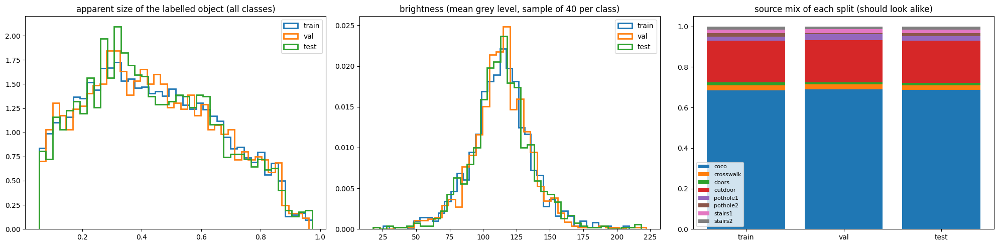

In [ ]:
# CELL 10b - SPLIT SIMILARITY (run after the verify cell): do train, val and test look alike? Compares object sizes, brightness and the source mix of the three splits of the FINAL dataset.
from scipy.stats import ks_2samp   # two-sample Kolmogorov-Smirnov test (0 = same distribution, 1 = completely different)
SPLITS = ('train', 'val', 'test')   # the three splits

def final_sizes(split, cid):   # apparent sizes (sqrt of box area) of the labelled objects of one class in one split of the FINAL dataset
    out = []   # one value per image
    for lp in (Path(FINAL_LOCAL) / split / folder_name(CLASS_LIST[cid])).glob('*.txt'):   # every label file of the class folder
        areas = [float(v[3]) * float(v[4]) for v in (l.split() for l in lp.read_text().splitlines()) if len(v) == 5 and int(v[0]) == cid]   # boxes of the folder's class
        if areas:   # at least one box of that class
            out.append(math.sqrt(max(areas)))   # the largest one is the size target
    return np.array(out)   # sizes

sz_split = {s: {c: final_sizes(s, c) for c in range(NC)} for s in SPLITS}   # sizes per split and class
print(f"{'class':13s}{'median size train/val/test':>30s}   KS train-val  KS train-test")   # header
worst = []   # classes whose splits differ a lot
for c in range(NC):   # every class
    ks_v = ks_2samp(sz_split['train'][c], sz_split['val'][c]).statistic   # train vs val
    ks_t = ks_2samp(sz_split['train'][c], sz_split['test'][c]).statistic   # train vs test
    meds = [float(np.median(sz_split[s][c])) for s in SPLITS]   # medians
    flag = '  <-- check' if max(ks_v, ks_t) > 0.25 else ''   # large differences deserve a look
    if flag:   # remember it
        worst.append(CLASS_LIST[c])   # class name
    print(f'{CLASS_LIST[c]:13s}{meds[0]:12.3f}{meds[1]:9.3f}{meds[2]:9.3f}{ks_v:15.3f}{ks_t:14.3f}{flag}')   # one row per class
print('classes whose size distribution differs between splits (KS > 0.25):', worst or 'none')   # summary

fig, ax = plt.subplots(1, 3, figsize=(20, 5))   # three charts
for s in SPLITS:   # one line per split
    ax[0].hist(np.concatenate([sz_split[s][c] for c in range(NC)]), bins=40, histtype='step', density=True, linewidth=2, label=s)   # size distribution of the whole split
ax[0].set_title('apparent size of the labelled object (all classes)'); ax[0].legend()   # decorate

def mean_grey(args):   # one final image -> its mean grey level (the picture is already 320 x 320 on local disk)
    g = cv2.imread(str(args), cv2.IMREAD_GRAYSCALE)   # read as grey
    return float(g.mean()) if g is not None else float('nan')   # brightness

br = {}   # brightness per split
rng_s = random.Random(SEED)   # repeatable sample
for s in SPLITS:   # every split
    files = []   # sampled files
    for c in range(NC):   # every class
        fl = sorted((Path(FINAL_LOCAL) / s / folder_name(CLASS_LIST[c])).glob('*.jpg'))   # its images
        files += rng_s.sample(fl, min(40, len(fl)))   # a random 40
    with ThreadPoolExecutor(WORKERS) as ex:   # read in parallel
        br[s] = np.array(list(ex.map(mean_grey, files)))   # brightness of every sampled image
    ax[1].hist(br[s], bins=40, histtype='step', density=True, linewidth=2, label=s)   # brightness distribution
ax[1].set_title('brightness (mean grey level, sample of 40 per class)'); ax[1].legend()   # decorate
print(f"brightness KS train-val {ks_2samp(br['train'], br['val']).statistic:.3f} | train-test {ks_2samp(br['train'], br['test']).statistic:.3f}")   # numbers

with open(f'{FINAL_LOCAL}/manifest.csv') as f:   # the manifest written by the save cell
    man2 = list(csv.DictReader(f))   # all rows
srcs2 = sorted({r['src'] for r in man2})   # datasets present
share = np.array([[sum(1 for r in man2 if r['split'] == s and r['src'] == src) for src in srcs2] for s in SPLITS], dtype=float)   # split x source counts
share /= share.sum(1, keepdims=True)   # share of each source inside a split
bottom = np.zeros(len(SPLITS))   # running bottom of the stacked bars
for j, src in enumerate(srcs2):   # one colour per source
    ax[2].bar(SPLITS, share[:, j], bottom=bottom, label=src)   # stacked bar
    bottom += share[:, j]   # move the bottom
ax[2].set_title('source mix of each split (should look alike)'); ax[2].legend(fontsize=8)   # decorate
save_fig('extra_split_similarity')   # save and show


In [ ]:
# CELL 9b - CHECK AND REPAIR THE DRIVE COPY: compares the dataset on the local disk with the copy on Drive (names, sizes, timestamps), copies what is missing or damaged, deletes duplicates and leftovers, then does the same for the .tar archive.
from google.colab import drive   # used to force Colab to write its queued changes to Drive
DELETE_EXTRAS = True   # delete files on Drive that are not in the local dataset (duplicates such as 'name (1).jpg', leftovers of an earlier run); they go to the Drive Trash
SYNC_ARCHIVE = True   # also check / copy final_dataset_v4.tar
TAR_LOCAL = '/content/final_dataset.tar'   # where the save cell wrote the archive on the local disk
assert Path(FINAL_LOCAL).exists(), 'the local dataset is gone (the runtime was reset), so there is nothing to copy from: re-run the build and save cells'   # stop early with a clear message

def tree(root):   # folder -> {relative path: (size in bytes, modified time)} for every file below it
    paths = [os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs]   # every file path
    def one(p):   # size and time of one file
        try:   # a Drive file may be unreadable
            st = os.stat(p)   # size and modified time
            return os.path.relpath(p, root), (st.st_size, st.st_mtime)   # relative name and its facts
        except OSError:   # unreadable
            return os.path.relpath(p, root), (-1, 0.0)   # mark it as damaged
    with ThreadPoolExecutor(WORKERS) as ex:   # stat many files in parallel
        return dict(ex.map(one, paths))   # the whole listing

def compare():   # local tree vs Drive tree -> (local, drive, missing, wrong size, extra)
    loc = tree(FINAL_LOCAL)   # what should exist
    drv = tree(FINAL_DRIVE) if os.path.exists(FINAL_DRIVE) else {}   # what is on Drive now
    missing = sorted(k for k in loc if k not in drv)   # not on Drive at all
    wrong = sorted(k for k in loc if k in drv and drv[k][0] != loc[k][0])   # on Drive but with a different size (half-written)
    extra = sorted(k for k in drv if k not in loc)   # on Drive but not part of the dataset (duplicates, leftovers)
    return loc, drv, missing, wrong, extra   # all five

def report(title):   # print the comparison and return it
    loc, drv, missing, wrong, extra = compare()   # measure
    print(f'--- {title} ---')   # heading
    print(f'files: local {len(loc):,} | Drive {len(drv):,} | missing on Drive {len(missing):,} | wrong size {len(wrong):,} | extra on Drive {len(extra):,}')   # totals
    for s in ('train', 'val', 'test'):   # per split
        n_l = sum(1 for k in loc if k.split(os.sep)[0] == s and k.endswith('.jpg'))   # local images
        n_d = sum(1 for k in drv if k.split(os.sep)[0] == s and k.endswith('.jpg'))   # Drive images
        print(f'  {s:5s} images: local {n_l:6,} | Drive {n_d:6,}')   # one line per split
    if drv:   # something is on Drive
        fmt = lambda t: time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(t))   # readable time
        times = [v[1] for v in drv.values() if v[0] >= 0]   # modified times of the Drive files
        print(f'  Drive files were written between {fmt(min(times))} and {fmt(max(times))}')   # first and last write
    if extra:   # show a few examples
        print('  examples of extra files:', extra[:5])   # so you can see what they are
    return loc, drv, missing, wrong, extra   # for the caller

loc, drv, missing, wrong, extra = report('BEFORE')   # state now

def copy_one(rel):   # copy one file from the local disk to Drive (retrying on Drive hiccups)
    src, dst = os.path.join(FINAL_LOCAL, rel), os.path.join(FINAL_DRIVE, rel)   # both paths
    os.makedirs(os.path.dirname(dst), exist_ok=True)   # make sure the class folder exists
    retry(lambda: shutil.copyfile(src, dst), tries=6, wait=5)   # copy, overwriting a half-written file
    return rel   # done

todo = missing + wrong   # everything that must be copied
if todo:   # something to do
    t0 = time.time()   # start the clock
    with ThreadPoolExecutor(WORKERS) as ex:   # copy in parallel
        for i, _ in enumerate(ex.map(copy_one, todo)):   # results arrive in order
            if (i + 1) % 2000 == 0:   # progress every 2000 files
                print(f'  copied {i + 1:,}/{len(todo):,} files ({time.time() - t0:.0f} s)')   # show it
    print(f'copied {len(todo):,} files in {time.time() - t0:.0f} s')   # summary
if DELETE_EXTRAS and extra:   # remove duplicates and leftovers
    for rel in extra:   # each extra file
        retry(lambda rel=rel: os.remove(os.path.join(FINAL_DRIVE, rel)))   # delete it (Drive keeps it in the Trash for 30 days)
    print(f'deleted {len(extra):,} extra files from Drive')   # summary

if SYNC_ARCHIVE:   # the archive is what the training notebook reads
    if not os.path.exists(TAR_LOCAL) or os.path.getmtime(TAR_LOCAL) < os.path.getmtime(f'{FINAL_LOCAL}/manifest.csv'):   # missing or older than the dataset
        subprocess.run(['tar', '-cf', TAR_LOCAL, '-C', str(Path(FINAL_LOCAL).parent), Path(FINAL_LOCAL).name], check=True)   # (re)build it from the local dataset
        print('rebuilt the local archive')   # tell the user
    n_local = os.path.getsize(TAR_LOCAL)   # size of the good archive
    n_drive = os.path.getsize(FINAL_TAR) if os.path.exists(FINAL_TAR) else -1   # size of the Drive archive (-1 = absent)
    print(f'archive: local {n_local / 1e6:,.1f} MB | Drive {n_drive / 1e6:,.1f} MB')   # compare
    if n_drive != n_local:   # absent or incomplete
        retry(lambda: shutil.copyfile(TAR_LOCAL, FINAL_TAR), tries=6, wait=10)   # copy the whole archive
        print('archive copied')   # done

print('flushing Colab\'s queued writes to Drive (this can take a few minutes) ...')   # explain the wait
drive.flush_and_unmount()   # forces every pending write to reach Drive
drive.mount('/content/drive')   # mount again so the checks below read what Drive really holds
loc, drv, missing, wrong, extra = report('AFTER (re-read from Drive)')   # state now
ok_folder = not (missing or wrong or extra)   # the folder is identical to the local dataset
print('folder copy is identical to the local dataset:', ok_folder)   # verdict
if SYNC_ARCHIVE:   # check the archive too
    same_size = os.path.exists(FINAL_TAR) and os.path.getsize(FINAL_TAR) == os.path.getsize(TAR_LOCAL)   # equal size
    list_n = lambda p: subprocess.run(['tar', '-tf', p], capture_output=True, text=True, check=True).stdout.count('\n')   # number of entries inside an archive (reads all of it)
    same_list = same_size and list_n(FINAL_TAR) == list_n(TAR_LOCAL)   # same number of entries
    print(f'archive on Drive: {os.path.getsize(FINAL_TAR) / 1e6:,.1f} MB, modified {time.strftime("%Y-%m-%d %H:%M:%S", time.localtime(os.path.getmtime(FINAL_TAR)))} | same size as local: {same_size} | readable with the same number of entries: {same_list}')   # verdict
    ok_folder = ok_folder and same_list   # overall
print('EVERYTHING IS ON DRIVE AND COMPLETE' if ok_folder else 'NOT COMPLETE YET: run this cell again (it only copies what is still missing)')   # final answer

--- BEFORE ---
files: local 54,084 | Drive 54,084 | missing on Drive 16 | wrong size 3 | extra on Drive 16
  train images: local 21,600 | Drive 21,600
  val   images: local  2,700 | Drive  2,700
  test  images: local  2,700 | Drive  2,700
  Drive files were written between 2026-11-05 17:36:14 and 2026-11-05 17:54:42
  examples of extra files: ['train/chair/coco_000000146078_584d3b.jpg', 'train/chair/coco_000000146078_584d3b.txt', 'train/crosswalk/crosswalk_train_01_4885_filename1025_33e406.jpg', 'train/crosswalk/crosswalk_train_01_4885_filename1025_33e406.txt', 'train/crosswalk/crosswalk_train_01_4885_filename1230_da81bc.jpg']
copied 19 files in 0 s
deleted 16 extra files from Drive
rebuilt the local archive
archive: local 1,122.5 MB | Drive 1,122.4 MB
archive copied
flushing Colab's queued writes to Drive (this can take a few minutes) ...
Mounted at /content/drive
--- AFTER (re-read from Drive) ---
files: local 54,084 | Drive 54,084 | missing on Drive 0 | wrong size 0 | extra on Drive

In [ ]:
# CHECK THE DRIVE COPY BY COUNTING: files per class and split in the Drive folder (and images inside the .tar), against what the dataset should hold. Stand-alone: it needs nothing from the other cells.
import os, subprocess   # file listing and the tar tool
DRIVE_DIR = '/content/drive/MyDrive/FYP/final_dataset_v4'   # the Drive folder to check
TAR_DRIVE = '/content/drive/MyDrive/FYP/final_dataset_v4.tar'   # the Drive archive to check
EXPECT = {'train': 800, 'val': 100, 'test': 100}   # images (and labels) expected per class in each split
CHECK_TAR_CONTENT = True   # also read the whole archive and count the images inside (takes a minute or two)
if not os.path.exists('/content/drive/MyDrive'):   # Drive is not mounted in this session
    from google.colab import drive   # Colab's helper
    drive.mount('/content/drive')   # mount it

names = [ln.split(' ', 1)[1] for ln in open(f'{DRIVE_DIR}/classes.txt').read().splitlines()]   # class names from classes.txt ('3 motorcycle' -> 'motorcycle')
problems = []   # everything that looks wrong
tot_img = {s: 0 for s in EXPECT}   # images found per split
tot_all = 0   # every file found
print(f"{'class':14s}" + ''.join(f'{s + " jpg/txt":>14s}' for s in EXPECT) + '   status')   # table header
for c in names:   # every class
    cells, bad = [], []   # the printed cells and the problems of this class
    for s, q in EXPECT.items():   # every split
        d = f'{DRIVE_DIR}/{s}/{c.replace(" ", "_")}'   # that class folder
        fs = os.listdir(d) if os.path.isdir(d) else []   # its file names (empty if the folder is missing)
        n_j = sum(f.endswith('.jpg') for f in fs)   # images
        n_t = sum(f.endswith('.txt') for f in fs)   # label files
        other = [f for f in fs if not f.endswith(('.jpg', '.txt')) and f != '_meta.json']   # anything unexpected (duplicates such as 'x (1).png', temp files)
        stems_j = {f[:-4] for f in fs if f.endswith('.jpg')}   # image names without extension
        stems_t = {f[:-4] for f in fs if f.endswith('.txt')}   # label names without extension
        tot_img[s] += n_j   # add to the split total
        tot_all += len(fs)   # add to the grand total
        cells.append(f'{n_j:>6d}/{n_t:<6d}  ')   # the printed cell
        if n_j != q or n_t != q:   # wrong number
            bad.append(f'{s}: {n_j} images / {n_t} labels, expected {q}')   # describe it
        if stems_j != stems_t:   # an image without its label or the other way round
            bad.append(f'{s}: {len(stems_j ^ stems_t)} images/labels without a partner')   # describe it
        if other:   # unexpected files
            bad.append(f'{s}: unexpected files {other[:3]}')   # show a few
    problems += [f'{c} -> {b}' for b in bad]   # remember them
    print(f'{c:14s}' + ''.join(f'{x:>14s}' for x in cells) + ('   OK' if not bad else '   <-- ' + '; '.join(bad)))   # one row per class
exp_tot = {s: q * len(names) for s, q in EXPECT.items()}   # expected images per split
print('\nimages per split  found:', tot_img, '| expected:', exp_tot)   # totals
print('all files in the class folders (images + labels + _meta.json):', f'{tot_all:,}', '| expected:', f'{2 * sum(exp_tot.values()) + len(EXPECT) * len(names):,}')   # grand total
top = sorted(f for f in os.listdir(DRIVE_DIR) if os.path.isfile(f'{DRIVE_DIR}/{f}'))   # files next to the split folders
print('top-level files:', top, '| expected: classes.txt, dataset_info.json, manifest.csv')   # should be exactly those three
if top != ['classes.txt', 'dataset_info.json', 'manifest.csv']:   # something missing or extra
    problems.append(f'top-level files are {top}')   # remember it

if os.path.exists(TAR_DRIVE):   # the archive is on Drive
    print(f'\narchive: {os.path.getsize(TAR_DRIVE) / 1e6:,.1f} MB')   # its size
    if CHECK_TAR_CONTENT:   # read it completely
        listing = subprocess.run(['tar', '-tf', TAR_DRIVE], capture_output=True, text=True, check=True).stdout.splitlines()   # every entry inside
        n_tar = sum(1 for e in listing if e.endswith('.jpg'))   # images inside
        print(f'images inside the archive: {n_tar:,} | expected: {sum(exp_tot.values()):,}')   # compare
        if n_tar != sum(exp_tot.values()):   # wrong number
            problems.append(f'archive holds {n_tar} images')   # remember it
else:   # no archive
    print('\narchive: NOT FOUND on Drive')   # say so
    problems.append('archive missing')   # remember it
print('\nALL COUNTS ARE CORRECT' if not problems else f'\n{len(problems)} PROBLEM(S): ' + ' | '.join(problems[:10]))   # final verdict

Mounted at /content/drive
class          train jpg/txt   val jpg/txt  test jpg/txt   status
person           800/800        100/100        100/100        OK
bicycle          800/800        100/100        100/100        OK
car              800/800        100/100        100/100        OK
motorcycle       800/800        100/100        100/100        OK
bus              800/800        100/100        100/100        OK
truck            800/800        100/100        100/100        OK
traffic light    800/800        100/100        100/100        OK
stop sign        800/800        100/100        100/100        OK
fire hydrant     800/800        100/100        100/100        OK
bench            800/800        100/100        100/100        OK
stairs           800/800        100/100        100/100        OK
chair            800/800        100/100        100/100        OK
couch            800/800        100/100        100/100        OK
table            800/800        100/100        100/100        O